## 1. Importarea bibliotecilor necesare



In [ ]:
# Importăm modulul os pentru a lucra cu fișiere și foldere.
import os

# Importăm modulul zipfile pentru a extrage arhiva occupancy+detection.zip.
import zipfile

# Importăm pandas pentru tabele de date de tip DataFrame.
import pandas as pd

# Importăm numpy pentru operații numerice.
import numpy as np

# Importăm matplotlib pentru grafice.
import matplotlib.pyplot as plt

# Importăm seaborn pentru grafice statistice.
import seaborn as sns

# Importăm time pentru a măsura timpul de antrenare și predicție.
import time

# Importăm combinations pentru a testa toate combinațiile posibile de senzori.
from itertools import combinations

# Importăm funcția care împarte datasetul în train și test.
from sklearn.model_selection import train_test_split

# Importăm cross_validate pentru validare încrucișată.
from sklearn.model_selection import cross_validate

# Importăm StratifiedKFold pentru a păstra proporția claselor în fiecare fold.
from sklearn.model_selection import StratifiedKFold

# Importăm StandardScaler pentru standardizarea variabilelor numerice.
from sklearn.preprocessing import StandardScaler

# Importăm Pipeline pentru a combina preprocessing-ul și modelul într-un singur obiect.
from sklearn.pipeline import Pipeline

# Importăm Logistic Regression, modelul principal al lucrării.
from sklearn.linear_model import LogisticRegression

# Importăm Decision Tree pentru comparație cu logistic regression.
from sklearn.tree import DecisionTreeClassifier

# Importăm Random Forest pentru comparație cu logistic regression.
from sklearn.ensemble import RandomForestClassifier

# Importăm SVM pentru comparație cu logistic regression.
from sklearn.svm import SVC

# Importăm metricile de evaluare pentru clasificare.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Importăm ROC-AUC pentru evaluarea capacității de separare între clase.
from sklearn.metrics import roc_auc_score

# Importăm confusion_matrix pentru analiza tipurilor de erori.
from sklearn.metrics import confusion_matrix

# Importăm classification_report pentru raport complet de clasificare.
from sklearn.metrics import classification_report

# Importăm roc_curve pentru desenarea curbei ROC.
from sklearn.metrics import roc_curve

## 2. Încărcarea datasetului din arhiva ZIP

Încarcă în Google Colab fișierul:

`occupancy+detection.zip`

Această celulă:
- caută automat arhiva ZIP;
- o extrage;
- caută fișierele `.txt` sau `.csv`;
- citește toate fișierele găsite;
- le combină într-un singur DataFrame numit `df`.



In [ ]:
# Căutăm toate fișierele ZIP încărcate în mediul Google Colab.
zip_files = [file for file in os.listdir("/content") if file.lower().endswith(".zip")]

# Verificăm dacă utilizatorul a încărcat cel puțin un fișier ZIP.
if len(zip_files) == 0:
    # Oprim execuția cu un mesaj clar dacă arhiva nu există.
    raise FileNotFoundError("Nu am găsit niciun fișier .zip. Încarcă occupancy+detection.zip în Colab și rulează din nou celula.")

# Preferăm automat arhiva care conține cuvântul occupancy în nume.
preferred_zip_files = [file for file in zip_files if "occupancy" in file.lower()]

# Alegem arhiva occupancy dacă există, altfel folosim primul ZIP găsit.
zip_path = preferred_zip_files[0] if len(preferred_zip_files) > 0 else zip_files[0]

# Afișăm numele arhivei folosite pentru verificare.
print("ZIP folosit:", zip_path)

# Definim folderul unde vor fi extrase fișierele din arhivă.
extract_dir = "/content/occupancy_data"

# Creăm folderul de extragere dacă nu există deja.
os.makedirs(extract_dir, exist_ok=True)

# Deschidem arhiva ZIP în modul citire.
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    # Extragem toate fișierele din arhivă în folderul definit.
    zip_ref.extractall(extract_dir)

    # Afișăm fișierele existente în arhivă.
    print("\nFișiere extrase din ZIP:")

    # Parcurgem fiecare nume de fișier din arhivă.
    for name in zip_ref.namelist():
        # Afișăm numele fișierului curent.
        print(" -", name)

# Inițializăm o listă în care vom salva căile fișierelor de date.
data_files = []

# Parcurgem recursiv folderul în care am extras arhiva.
for root, dirs, files_in_dir in os.walk(extract_dir):
    # Parcurgem fiecare fișier din folderul curent.
    for file in files_in_dir:
        # Verificăm dacă fișierul are extensia .txt sau .csv.
        if file.lower().endswith((".txt", ".csv")):
            # Construim calea completă către fișier.
            full_path = os.path.join(root, file)

            # Adăugăm calea fișierului în lista de fișiere de date.
            data_files.append(full_path)

# Afișăm fișierele de date găsite.
print("\nFișiere de date găsite:")

# Parcurgem lista fișierelor de date.
for file_path in data_files:
    # Afișăm calea completă a fiecărui fișier de date.
    print(" -", file_path)

# Verificăm dacă am găsit cel puțin un fișier de date.
if len(data_files) == 0:
    # Oprim execuția dacă arhiva nu conține fișiere .txt sau .csv.
    raise FileNotFoundError("Nu am găsit fișiere .txt sau .csv în arhiva ZIP.")

# Inițializăm lista în care vom salva DataFrame-urile citite din fișiere.
dfs = []

# Parcurgem fiecare fișier de date găsit.
for file_path in data_files:
    # Citim fișierul ca tabel CSV, deoarece fișierele UCI sunt separate prin virgulă.
    temp_df = pd.read_csv(file_path)

    # Adăugăm o coloană cu numele fișierului sursă pentru trasabilitate.
    temp_df["source_file"] = os.path.basename(file_path)

    # Adăugăm tabelul citit în lista de DataFrame-uri.
    dfs.append(temp_df)

# Combinăm toate fișierele de date într-un singur DataFrame.
df = pd.concat(dfs, ignore_index=True)

# Eliminăm coloana Unnamed: 0 dacă există, deoarece aceasta este doar un index salvat în fișier.
if "Unnamed: 0" in df.columns:
    # Ștergem coloana de index inutilă.
    df = df.drop(columns=["Unnamed: 0"])

# Afișăm dimensiunea datasetului combinat.
print("\nDataset combinat shape:", df.shape)

# Afișăm lista coloanelor pentru verificare.
print("\nColoane disponibile:")
print(df.columns.tolist())

# Afișăm primele 5 rânduri ale datasetului încărcat din ZIP.
df.head(10)

ZIP folosit: occupancy+detection.zip

Fișiere extrase din ZIP:
 - datatest.txt
 - datatest2.txt
 - datatraining.txt

Fișiere de date găsite:
 - /content/occupancy_data/datatest2.txt
 - /content/occupancy_data/datatest.txt
 - /content/occupancy_data/datatraining.txt

Dataset combinat shape: (20560, 8)

Coloane disponibile:
['date', 'Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio', 'Occupancy', 'source_file']


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy,source_file
0,2015-02-11 14:48:00,21.7600,31.133333,437.333333,1029.666667,0.005021,1,datatest2.txt
1,2015-02-11 14:49:00,21.7900,31.000000,437.333333,1000.000000,0.005009,1,datatest2.txt
2,2015-02-11 14:50:00,21.7675,31.122500,434.000000,1003.750000,0.005022,1,datatest2.txt
3,2015-02-11 14:51:00,21.7675,31.122500,439.000000,1009.500000,0.005022,1,datatest2.txt
4,2015-02-11 14:51:59,21.7900,31.133333,437.333333,1005.666667,0.005030,1,datatest2.txt
5,2015-02-11 14:53:00,21.7600,31.260000,437.333333,1014.333333,0.005042,1,datatest2.txt
6,2015-02-11 14:54:00,21.7900,31.197500,434.000000,1018.500000,0.005041,1,datatest2.txt
7,2015-02-11 14:55:00,21.7900,31.393333,437.333333,1018.666667,0.005073,1,datatest2.txt
8,2015-02-11 14:55:59,21.7900,31.317500,434.000000,1022.000000,0.005060,1,datatest2.txt
9,2015-02-11 14:57:00,21.7900,31.463333,437.333333,1027.333333,0.005084,1,datatest2.txt


## 4. Verificarea coloanelor

Această celulă ma ajută să vad exact ce coloane există în dataset.
Este important deoarece numele coloanelor trebuie folosite corect în cod.

In [ ]:
# Afișăm lista coloanelor din dataset.
print(df.columns)

# Afișăm dimensiunea datasetului: număr de rânduri și număr de coloane.
print("Dataset shape:", df.shape)

Index(['date', 'Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio',
       'Occupancy', 'source_file'],
      dtype='object')
Dataset shape: (20560, 8)


## 37. Explicația variabilelor și a clasei `Occupancy`



Datasetul conține măsurători de mediu dintr-o cameră. Aceste măsurători sunt folosite de model pentru a estima probabilitatea ca încăperea să fie ocupată.

Interpretarea clasei țintă:

- `Occupancy = 0` înseamnă cameră liberă;
- `Occupancy = 1` înseamnă cameră ocupată.

!! modelul nu măsoară direct senzorii. Senzorii măsoară valorile fizice, iar modelul Logistic Regression folosește aceste valori pentru a calcula probabilitatea:

`P(Occupancy = 1 | valorile senzorilor)`

Adică probabilitatea ca încăperea să fie ocupată, având în vedere valorile măsurate.

In [ ]:
# Construim un tabel explicativ pentru variabilele din dataset.
variable_explanation = pd.DataFrame({
    # Coloana Variable conține numele variabilei exact ca în dataset.
    "Variable": ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio", "Occupancy"],

    # Coloana Meaning explică ce reprezintă fiecare variabilă.
    "Meaning": [
        "Temperatura aerului din cameră",
        "Umiditatea relativă a aerului",
        "Intensitatea luminii din cameră",
        "Concentrația de dioxid de carbon din aer",
        "Raportul de umiditate, calculat din temperatură și umiditate",
        "Clasa țintă: 0 = cameră liberă, 1 = cameră ocupată"
    ],

    # Coloana Typical_measurement explică modul obișnuit de măsurare.
    "Typical_measurement": [
        "Senzor de temperatură, de exemplu DHT22, BME280 sau senzor integrat",
        "Senzor de umiditate, de exemplu DHT22, BME280 sau senzor integrat",
        "Senzor de lumină, de exemplu LDR, fotorezistor, BH1750 sau senzor de iluminare",
        "Senzor CO2, de exemplu NDIR, mai scump și mai complex decât senzorii simpli",
        "Valoare derivată matematic, nu este obligatoriu un senzor separat",
        "Etichetă din dataset, nu senzor fizic"
    ],

    # Coloana Difficulty arată cât de ușor este de obținut variabila într-un sistem robotic.
    "Difficulty": [
        "Ușor",
        "Ușor",
        "Foarte ușor",
        "Mediu spre dificil",
        "Ușor dacă avem deja temperatură și umiditate",
        "Nu se măsoară direct; este clasa reală folosită pentru antrenare"
    ]
})

# Afișăm tabelul explicativ.
variable_explanation

,Variable,Meaning,Typical_measurement,Difficulty
0,Temperature,Temperatura aerului din cameră,"Senzor de temperatură, de exemplu DHT22, BME28...",Ușor
1,Humidity,Umiditatea relativă a aerului,"Senzor de umiditate, de exemplu DHT22, BME280 ...",Ușor
2,Light,Intensitatea luminii din cameră,"Senzor de lumină, de exemplu LDR, fotorezistor...",Foarte ușor
3,CO2,Concentrația de dioxid de carbon din aer,"Senzor CO2, de exemplu NDIR, mai scump și mai ...",Mediu spre dificil
4,HumidityRatio,"Raportul de umiditate, calculat din temperatur...","Valoare derivată matematic, nu este obligatori...",Ușor dacă avem deja temperatură și umiditate
5,Occupancy,"Clasa țintă: 0 = cameră liberă, 1 = cameră ocu...","Etichetă din dataset, nu senzor fizic",Nu se măsoară direct; este clasa reală folosit...


## 5. Selectarea variabilelor și curățarea datelor

Aici aleg cele 5 variabile de intrare și variabila țintă.

Cele 5 variabile sunt considerate senzori sau măsurători de mediu:
- `Temperature`;
- `Humidity`;
- `Light`;
- `CO2`;
- `HumidityRatio`.

Curățarea datelor este necesară pentru că modelele de machine learning nu pot lucra corect cu valori lipsă (`NaN`) sau valori nenumerice.

In [ ]:
# Definim numele coloanei țintă.
target = "Occupancy"

# Definim lista celor 5 senzori folosiți ca variabile de intrare.
all_features = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]

# Selectăm doar coloanele de care avem nevoie pentru lucrare.
df_clean = df[all_features + [target]].copy()

# Convertim fiecare coloană în format numeric.
for col in all_features + [target]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Eliminăm rândurile care conțin valori lipsă.
df_clean = df_clean.dropna()

# Convertim target-ul în valori întregi 0 sau 1.
df_clean[target] = df_clean[target].astype(int)

# Afișăm dimensiunea datasetului după curățare.
print("Clean dataset shape:", df_clean.shape)

# Verificăm dacă mai există valori lipsă.
print(df_clean.isna().sum())

# Afișăm primele 5 rânduri din datasetul curățat.
df_clean.head()

Clean dataset shape: (20560, 6)
Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64


,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,21.7600,31.133333,437.333333,1029.666667,0.005021,1
1,21.7900,31.000000,437.333333,1000.000000,0.005009,1
2,21.7675,31.122500,434.000000,1003.750000,0.005022,1
3,21.7675,31.122500,439.000000,1009.500000,0.005022,1
4,21.7900,31.133333,437.333333,1005.666667,0.005030,1


## 6. Analiza descriptivă a datelor

Această celulă afișează statistici de bază:
- media;
- deviația standard;
- minimul;
- maximul;
- quartilele.

Ajută la înțelegerea intervalelor în care se află valorile senzorilor.

In [ ]:
# Afișăm statistici descriptive pentru toate coloanele numerice.
df_clean.describe()

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
count,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000
mean,20.906212,27.655925,130.756622,690.553276,0.004228,0.231031
std,1.055315,4.982154,210.430875,311.201281,0.000768,0.421503
min,19.000000,16.745000,0.000000,412.750000,0.002674,0.000000
25%,20.200000,24.500000,0.000000,460.000000,0.003719,0.000000
50%,20.700000,27.290000,0.000000,565.416667,0.004292,0.000000
75%,21.525000,31.290000,301.000000,804.666667,0.004832,0.000000
max,24.408333,39.500000,1697.250000,2076.500000,0.006476,1.000000


## 7. Distribuția claselor Occupancy

Verific câte exemple avem pentru:
- cameră liberă (`0`);
- cameră ocupată (`1`).

Acest pas este important deoarece un dataset foarte dezechilibrat poate face ca accuracy să fie înșelătoare.

Occupancy
0    15810
1     4750
Name: count, dtype: int64


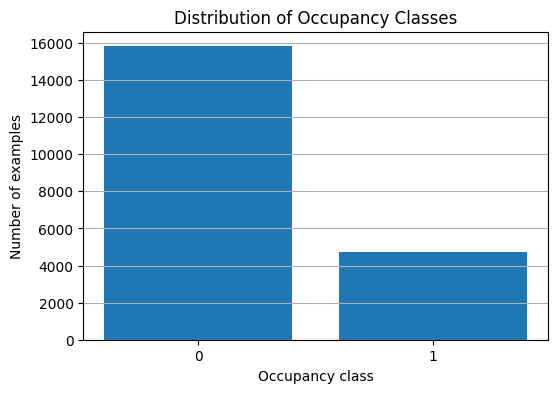

In [ ]:
# Numărăm câte exemple există pentru fiecare clasă.
class_counts = df_clean[target].value_counts()

# Afișăm numărul de exemple pentru fiecare clasă.
print(class_counts)

# Desenăm distribuția claselor.
plt.figure(figsize=(6, 4))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xlabel("Occupancy class")
plt.ylabel("Number of examples")
plt.title("Distribution of Occupancy Classes")
plt.grid(axis="y")
plt.show()

## 8. Matricea de corelație

Matricea de corelație arată relațiile liniare dintre variabile.

Aceasta este utilă pentru:
- identificarea senzorilor puternic legați de `Occupancy`;
- observarea variabilelor redundante;
- justificarea reducerii numărului de senzori.

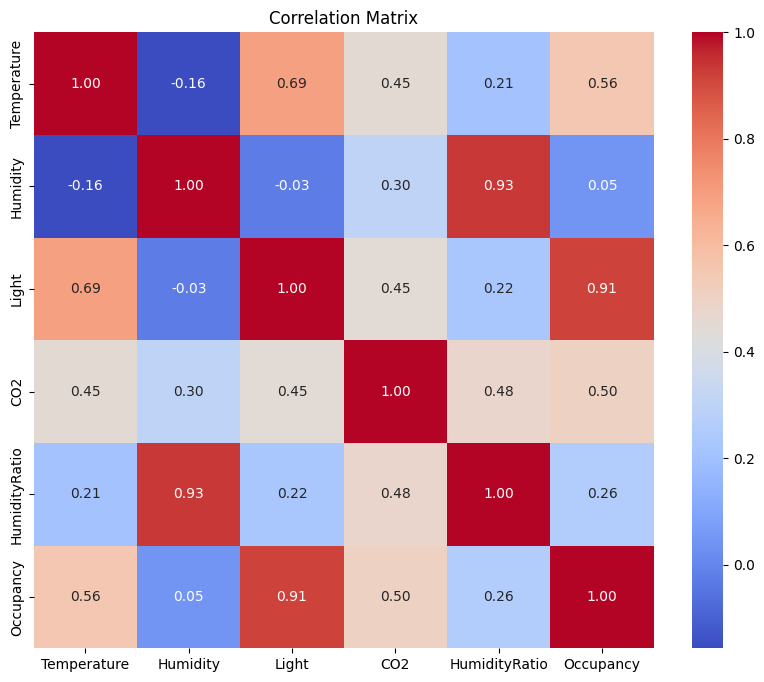

In [ ]:
# Calculăm matricea de corelație pentru datasetul curățat.
corr = df_clean.corr(numeric_only=True)

# Setăm dimensiunea figurii.
plt.figure(figsize=(10, 8))

# Desenăm matricea de corelație.
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

# Adăugăm titlul graficului.
plt.title("Correlation Matrix")

# Afișăm graficul.
plt.show()

## 9. Corelația fiecărui senzor cu Occupancy

Aici extrag doar corelațiile dintre fiecare senzor și target-ul `Occupancy`.

Acest tabel ajută la justificarea ideii că nu toți senzorii contribuie în aceeași măsură la predicție.

In [ ]:
# Selectăm corelația fiecărei variabile cu Occupancy.
correlation_with_target = corr[target].drop(target)

# Sortăm corelațiile descrescător după valoarea absolută.
correlation_with_target = correlation_with_target.reindex(
    correlation_with_target.abs().sort_values(ascending=False).index
)

# Transformăm rezultatul într-un DataFrame pentru afișare mai clară.
correlation_df = correlation_with_target.reset_index()

# Redenumim coloanele.
correlation_df.columns = ["Feature", "Correlation with Occupancy"]

# Afișăm tabelul.
correlation_df

,Feature,Correlation with Occupancy
0,Light,0.914850
1,Temperature,0.555610
2,CO2,0.501582
3,HumidityRatio,0.257324
4,Humidity,0.046240


## 10. Pairplot pentru relațiile dintre variabile

Pairplot-ul arată relațiile dintre variabile și separarea dintre clase.

Este util pentru partea de analiză exploratorie

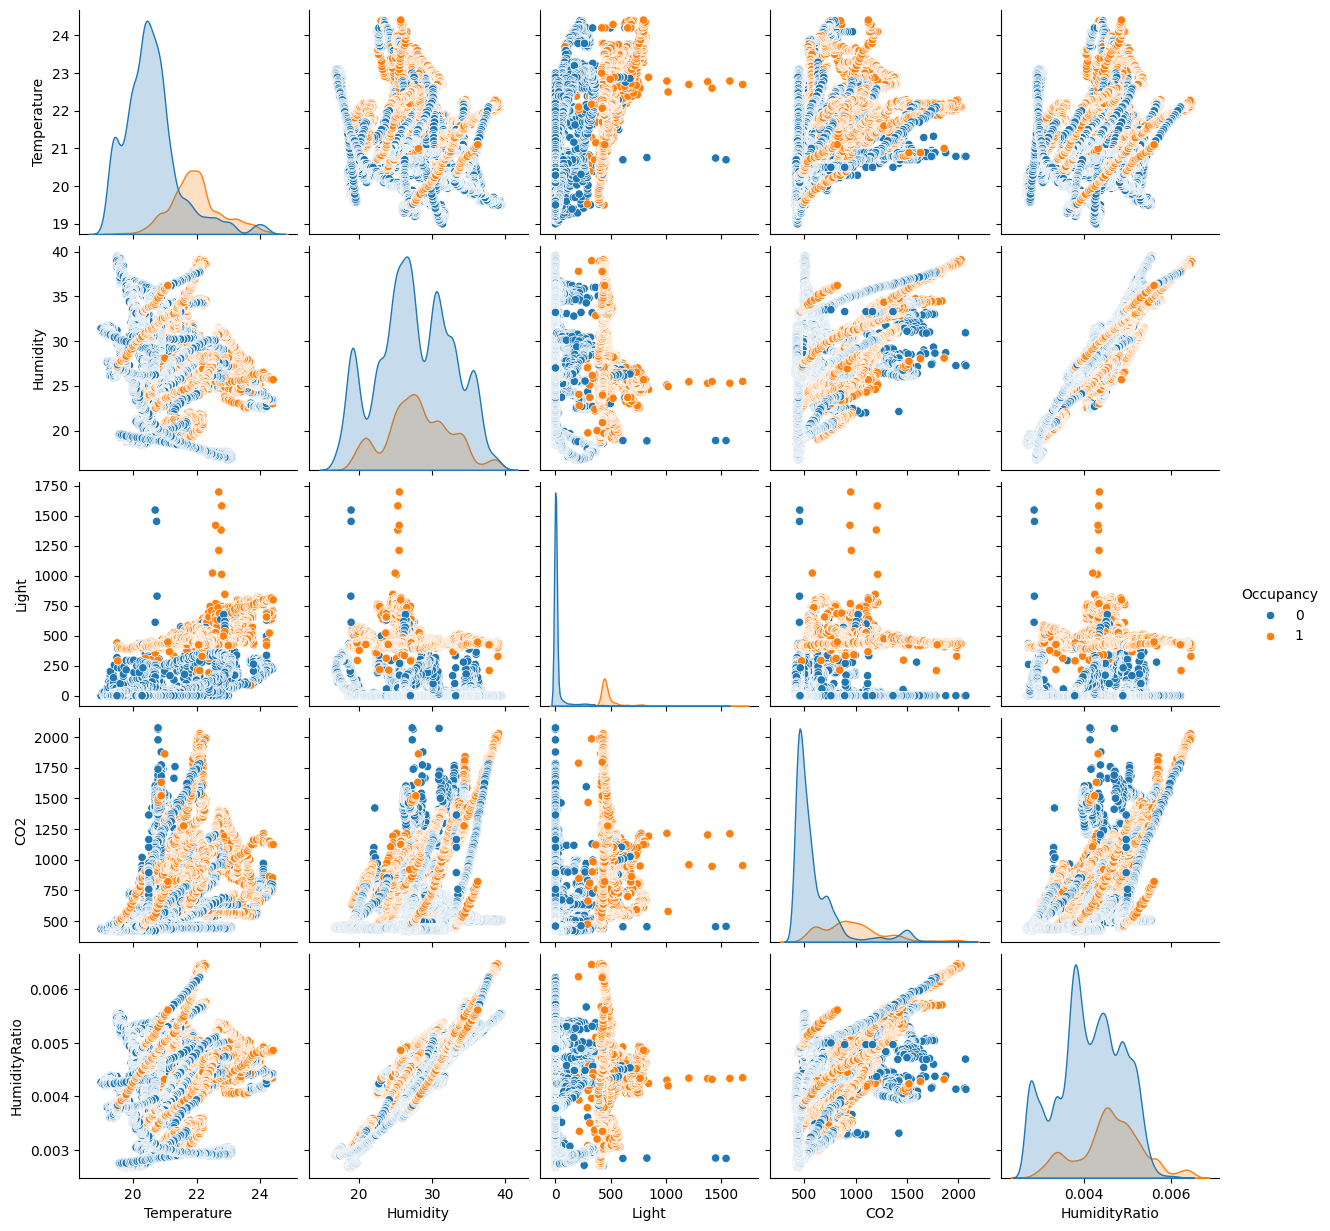

In [ ]:
# Construim un pairplot pentru a vedea relațiile dintre senzori și Occupancy.
sns.pairplot(
    df_clean,
    hue="Occupancy"
)

# Afișăm graficul.
plt.show()

## 11. Separarea variabilelor de intrare și a targetului

Aici separ:
- `X` = valorile senzorilor;
- `y` = clasa pe care vrem să o prezicem, adică `Occupancy`.

Aceasta este structura standard pentru modelele de machine learning.

In [ ]:
# X conține cele 5 variabile de intrare.
X = df_clean[all_features]

# y conține variabila țintă Occupancy.
y = df_clean[target]

# Afișăm dimensiunile pentru verificare.
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20560, 5)
y shape: (20560,)


## 12. Împărțirea în train și test

Împărt datele în:
- set de antrenare: 75%;
- set de testare: 25%.

Modelul învață pe train și este evaluat pe test.

Folosesc `stratify=y` pentru a păstra proporția claselor în ambele seturi.

In [ ]:
# Împărțim datele în set de antrenare și set de testare.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Afișăm dimensiunile seturilor rezultate.
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (15420, 5)
X_test: (5140, 5)
y_train: (15420,)
y_test: (5140,)


## 13. Modelul principal: Logistic Regression

Acesta este modelul principal

Folosesc un `Pipeline` cu două etape:
1. `StandardScaler` — standardizează senzorii;
2. `LogisticRegression` — antrenează modelul de clasificare.

Standardizarea este importantă deoarece senzorii au scale diferite:
- CO2 poate avea valori de sute sau mii;
- HumidityRatio are valori foarte mici.

In [ ]:
# Construim pipeline-ul pentru logistic regression.
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000))
])

# Antrenăm modelul pe datele de train.
lr_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('lr', LogisticRegression(max_iter=1000))])

## 14. Predicții și probabilități

Logistic Regression poate produce două tipuri de rezultate:

1. `predict()`  
   Returnează clasa finală: `0` sau `1`.

2. `predict_proba()`  
   Returnează probabilitatea pentru fiecare clasă.

Este importantă probabilitatea pentru clasa `1`, adică probabilitatea ca încăperea să fie ocupată.

In [ ]:
# Calculăm predicțiile binare 0 sau 1.
y_pred = lr_model.predict(X_test)

# Calculăm probabilitățile pentru clasa 1, adică Occupancy = 1.
y_prob = lr_model.predict_proba(X_test)[:, 1]

# Afișăm primele 10 probabilități.
print(y_prob[:10])

[1.94520946e-04 9.42354268e-04 1.18419425e-04 1.40063659e-04
 1.04774041e-04 1.12431990e-02 1.61751774e-04 7.53886218e-04
 1.05836408e-01 4.66681867e-04]


## 15. Evaluarea modelului Logistic Regression

Folosesc mai multe metrici, nu doar accuracy:
- `Accuracy`: câte predicții totale sunt corecte;
- `Precision`: cât de corecte sunt predicțiile pozitive;
- `Recall`: câte cazuri pozitive reale sunt detectate;
- `F1-score`: echilibru între precision și recall;
- `ROC-AUC`: capacitatea modelului de a separa clasele.

In [ ]:
# Calculăm accuracy.
accuracy = accuracy_score(y_test, y_pred)

# Calculăm precision.
precision = precision_score(y_test, y_pred)

# Calculăm recall.
recall = recall_score(y_test, y_pred)

# Calculăm F1-score.
f1 = f1_score(y_test, y_pred)

# Calculăm ROC-AUC folosind probabilitățile.
roc_auc = roc_auc_score(y_test, y_prob)

# Afișăm rezultatele.
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("ROC-AUC:", roc_auc)

Accuracy: 0.9889105058365759
Precision: 0.959349593495935
Recall: 0.9941027801179444
F1-score: 0.9764170459247
ROC-AUC: 0.9933283051422881


## 16. Classification report

Acest raport afișează metricile pentru fiecare clasă:
- clasa `0`: cameră liberă;
- clasa `1`: cameră ocupată.

Este util pentru a vedea dacă modelul funcționează bine pentru ambele clase.

In [ ]:
# Afișăm raportul complet de clasificare.
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      3953
           1       0.96      0.99      0.98      1187

    accuracy                           0.99      5140
   macro avg       0.98      0.99      0.98      5140
weighted avg       0.99      0.99      0.99      5140



## 17. Confusion Matrix

Matricea de confuzie arată:
- True Negative: camera era liberă și modelul a prezis liber;
- False Positive: camera era liberă, dar modelul a prezis ocupat;
- False Negative: camera era ocupată, dar modelul a prezis liber;
- True Positive: camera era ocupată și modelul a prezis ocupat.

În robotică, `False Negative` este mai periculos, deoarece robotul poate crede că zona este sigură când de fapt este ocupată.

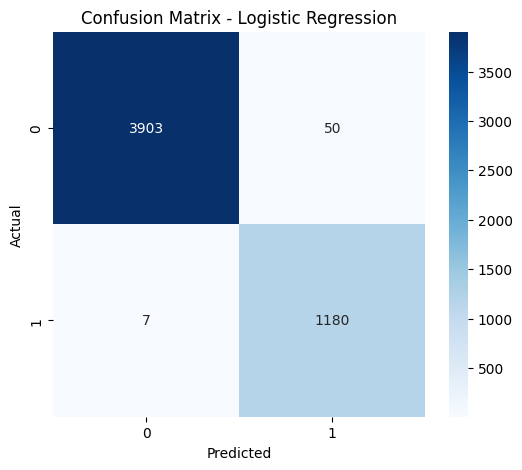

In [ ]:
# Calculăm matricea de confuzie.
cm = confusion_matrix(y_test, y_pred)

# Setăm dimensiunea figurii.
plt.figure(figsize=(6, 5))

# Desenăm matricea de confuzie.
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

# Eticheta axei X.
plt.xlabel("Predicted")

# Eticheta axei Y.
plt.ylabel("Actual")

# Titlul graficului.
plt.title("Confusion Matrix - Logistic Regression")

# Afișăm graficul.
plt.show()

## 18. ROC Curve

Curba ROC arată relația dintre:
- rata de true positives;
- rata de false positives.

ROC-AUC apropiat de 1 indică un model foarte bun.

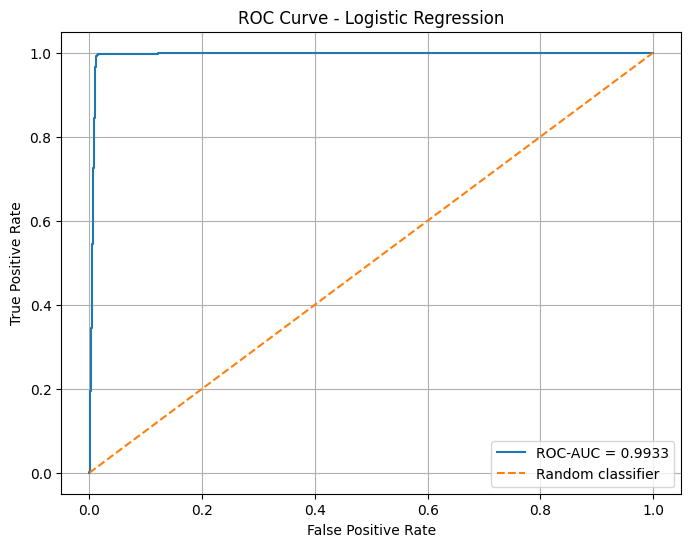

In [ ]:
# Calculăm valorile pentru curba ROC.
fpr, tpr, roc_thresholds = roc_curve(y_test, y_prob)

# Setăm dimensiunea graficului.
plt.figure(figsize=(8, 6))

# Desenăm curba ROC.
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")

# Desenăm diagonala care reprezintă un model aleator.
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

# Eticheta axei X.
plt.xlabel("False Positive Rate")

# Eticheta axei Y.
plt.ylabel("True Positive Rate")

# Titlul graficului.
plt.title("ROC Curve - Logistic Regression")

# Afișăm legenda.
plt.legend()

# Adăugăm grid.
plt.grid(True)

# Afișăm graficul.
plt.show()

## 19. Interpretarea coeficienților Logistic Regression

Un avantaj important al logistic regression este interpretabilitatea.

Coeficient pozitiv:
- creșterea variabilei crește probabilitatea de `Occupancy = 1`.

Coeficient negativ:
- creșterea variabilei scade probabilitatea de `Occupancy = 1`.



In [ ]:
# Extragem coeficienții învățați de model.
coefficients = lr_model.named_steps["lr"].coef_[0]

# Construim un tabel cu variabilele și coeficienții lor.
coef_df = pd.DataFrame({
    "Feature": all_features,
    "Coefficient": coefficients
})

# Sortăm coeficienții după valoarea absolută.
coef_df["Absolute Coefficient"] = coef_df["Coefficient"].abs()

# Afișăm coeficienții ordonați descrescător după importanță.
coef_df.sort_values(by="Absolute Coefficient", ascending=False)

,Feature,Coefficient,Absolute Coefficient
2,Light,5.092389,5.092389
3,CO2,1.155946,1.155946
0,Temperature,-0.991520,0.991520
4,HumidityRatio,0.229912,0.229912
1,Humidity,0.199775,0.199775


## 20. Grafic pentru coeficienți

Acest grafic arată vizual ce variabile influențează cel mai mult modelul.

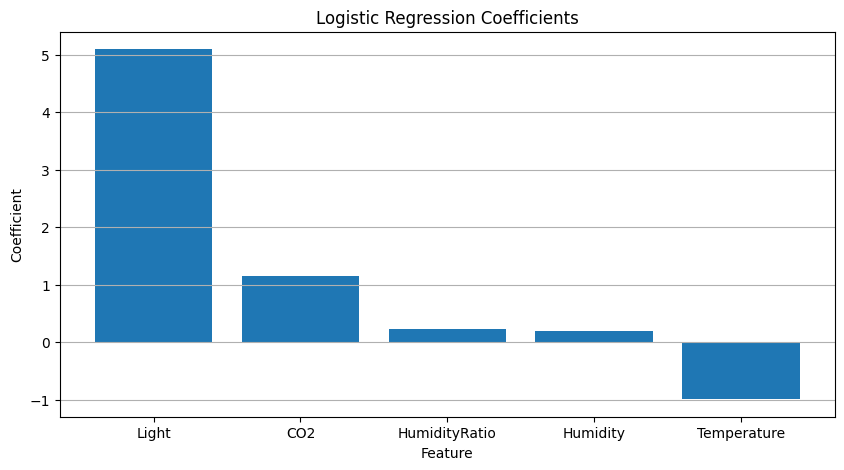

In [ ]:
# Sortăm coeficienții pentru afișare.
coef_plot_df = coef_df.sort_values(by="Coefficient", ascending=False)

# Setăm dimensiunea figurii.
plt.figure(figsize=(10, 5))

# Desenăm graficul de tip bar.
plt.bar(
    coef_plot_df["Feature"],
    coef_plot_df["Coefficient"]
)

# Eticheta axei X.
plt.xlabel("Feature")

# Eticheta axei Y.
plt.ylabel("Coefficient")

# Titlul graficului.
plt.title("Logistic Regression Coefficients")

# Adăugăm grid pe axa Y.
plt.grid(axis="y")

# Afișăm graficul.
plt.show()

## 21. Cross-validation pentru stabilitatea modelului

Până acum am evaluat modelul pe o singură împărțire train-test.

Cross-validation verifică dacă modelul este stabil pe mai multe împărțiri ale datelor.

Folosesc 5-fold cross-validation:
- datasetul este împărțit în 5 părți;
- modelul este antrenat și testat de 5 ori;
- calculez media și deviația standard a metricilor.

In [ ]:
# Definim metoda de cross-validation cu 5 fold-uri.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Definim modelul folosit în cross-validation.
lr_cv_model = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000))
])

# Definim metricile evaluate.
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Rulăm cross-validation.
cv_results = cross_validate(
    lr_cv_model,
    X,
    y,
    cv=cv,
    scoring=scoring
)

# Construim un tabel cu media și deviația standard.
cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Mean": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std(),
        cv_results["test_roc_auc"].std()
    ]
})

# Afișăm rezultatele.
cv_summary

,Metric,Mean,Standard Deviation
0,Accuracy,0.988862,0.000805
1,Precision,0.958266,0.004328
2,Recall,0.995158,0.002063
3,F1-score,0.976354,0.001652
4,ROC-AUC,0.994741,0.000816


## 22. Comparație cu alți algoritmi

Comparare Logistic Regression cu:
- Decision Tree;
- Random Forest;
- SVM.

Scopul nu este neapărat ca Logistic Regression să fie cel mai bun, ci să justific de ce este potrivit:
- este interpretabil;
- este rapid;
- produce probabilități;
- este potrivit pentru decizii în timp real.

In [ ]:
# Definim modelele pe care vrem să le comparăm.
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=42))
    ])
}

# Inițializăm o listă în care salvăm rezultatele.
model_results = []

# Parcurgem fiecare model.
for name, model in models.items():

    # Pornim cronometrul pentru antrenare.
    start_train = time.time()

    # Antrenăm modelul.
    model.fit(X_train, y_train)

    # Calculăm timpul de antrenare.
    train_time = time.time() - start_train

    # Pornim cronometrul pentru predicție.
    start_pred = time.time()

    # Calculăm predicțiile.
    y_pred_model = model.predict(X_test)

    # Calculăm timpul de predicție.
    inference_time = time.time() - start_pred

    # Calculăm probabilitățile pentru clasa 1.
    y_prob_model = model.predict_proba(X_test)[:, 1]

    # Salvăm metricile în listă.
    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred_model),
        "Precision": precision_score(y_test, y_pred_model),
        "Recall": recall_score(y_test, y_pred_model),
        "F1-score": f1_score(y_test, y_pred_model),
        "ROC-AUC": roc_auc_score(y_test, y_prob_model),
        "Training Time": train_time,
        "Inference Time": inference_time
    })

# Transformăm lista într-un DataFrame.
model_results_df = pd.DataFrame(model_results)

# Afișăm tabelul.
model_results_df

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time,Inference Time
0,Logistic Regression,0.988911,0.959350,0.994103,0.976417,0.993328,0.022684,0.002407
1,Decision Tree,0.990272,0.984655,0.973041,0.978814,0.984244,0.068923,0.002124
2,Random Forest,0.992996,0.982397,0.987363,0.984874,0.998583,1.503382,0.052759
3,SVM,0.989494,0.960195,0.995788,0.977667,0.991658,3.155542,0.131968


## 23. Sistem Rule-Based pentru comparație

Un sistem rule-based folosește reguli fixe, de exemplu:
- dacă lumina este mare;
- sau dacă CO2 este mare;
- atunci camera este considerată ocupată.

Această comparație este importantă pentru că arată diferența dintre:
- reguli manuale;
- model probabilistic care învață din date.

In [ ]:
# Definim o funcție simplă bazată pe reguli.
def rule_based_system(row):

    # Dacă lumina este mare sau CO2 este mare, considerăm camera ocupată.
    if row["Light"] > 400 or row["CO2"] > 900:
        return 1

    # Altfel, considerăm camera liberă.
    else:
        return 0

# Aplicăm sistemul rule-based pe fiecare rând din X_test.
y_rule_pred = X_test.apply(rule_based_system, axis=1)

# Calculăm rezultatele sistemului rule-based.
rule_results = pd.DataFrame([{
    "Model": "Rule-Based System",
    "Accuracy": accuracy_score(y_test, y_rule_pred),
    "Precision": precision_score(y_test, y_rule_pred),
    "Recall": recall_score(y_test, y_rule_pred),
    "F1-score": f1_score(y_test, y_rule_pred),
    "ROC-AUC": np.nan,
    "Training Time": 0,
    "Inference Time": np.nan
}])

# Combinăm rezultatele ML cu rezultatul rule-based.
comparison_with_rules = pd.concat(
    [model_results_df, rule_results],
    ignore_index=True
)

# Afișăm comparația.
comparison_with_rules

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time,Inference Time
0,Logistic Regression,0.988911,0.959350,0.994103,0.976417,0.993328,0.022684,0.002407
1,Decision Tree,0.990272,0.984655,0.973041,0.978814,0.984244,0.068923,0.002124
2,Random Forest,0.992996,0.982397,0.987363,0.984874,0.998583,1.503382,0.052759
3,SVM,0.989494,0.960195,0.995788,0.977667,0.991658,3.155542,0.131968
4,Rule-Based System,0.921984,0.751923,0.988206,0.854023,NaN,0.000000,NaN


## 24. Classification Report and Confusion Matrix for Decision Tree, Random Forest, and SVM

Pentru fiecare model antrenăm, calculăm predicțiile pe setul de test și afișăm raportul complet de clasificare plus matricea de confuzie individuală.


Classification Report - Decision Tree
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3953
           1       0.98      0.97      0.98      1187

    accuracy                           0.99      5140
   macro avg       0.99      0.98      0.99      5140
weighted avg       0.99      0.99      0.99      5140



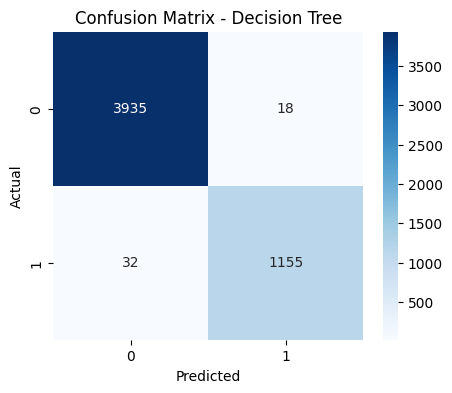


Classification Report - Random Forest
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      3953
           1       0.98      0.99      0.98      1187

    accuracy                           0.99      5140
   macro avg       0.99      0.99      0.99      5140
weighted avg       0.99      0.99      0.99      5140



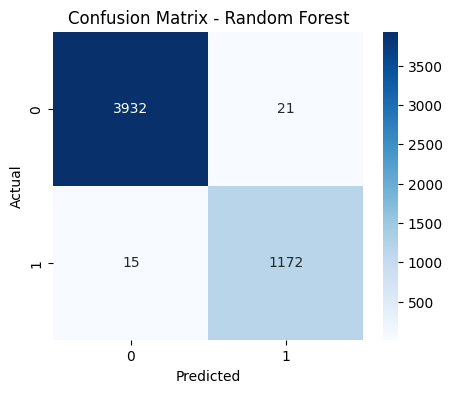


Classification Report - SVM
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      3953
           1       0.96      1.00      0.98      1187

    accuracy                           0.99      5140
   macro avg       0.98      0.99      0.99      5140
weighted avg       0.99      0.99      0.99      5140



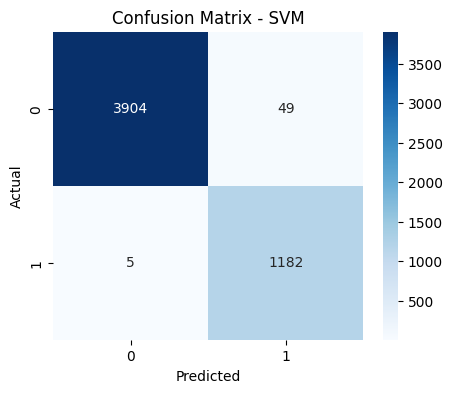

In [ ]:
# Definim din nou modelele pentru a putea inspecta fiecare în detaliu.
fitted_models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=42))
    ])
}

# Parcurgem fiecare model, îl antrenăm și afișăm raportul complet de clasificare.
for name, model in fitted_models.items():

    # Antrenăm modelul pe datele de train.
    model.fit(X_train, y_train)

    # Calculăm predicțiile pe setul de test.
    y_pred_model = model.predict(X_test)

    # Afișăm numele modelului.
    print(f"\n{'='*60}")
    print(f"Classification Report - {name}")
    print('='*60)

    # Afișăm raportul complet de clasificare.
    print(classification_report(y_test, y_pred_model))

    # Calculăm matricea de confuzie.
    cm_model = confusion_matrix(y_test, y_pred_model)

    # Desenăm matricea de confuzie.
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm_model, annot=True, fmt="d", cmap="Blues")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    # Salvăm modelul antrenat pentru pasul următor.
    fitted_models[name] = model

## 25. Matrici de confuzie comparate (Decision Tree, Random Forest, SVM)

O singură figură cu cele trei matrici de confuzie una lângă alta, pentru comparație vizuală rapidă.

In [ ]:
"""
Combined confusion matrix figure: Decision Tree, Random Forest, SVM
side by side (1 row x 3 columns), smaller size.

This replaces the three separate figures (3.6, 3.7, 3.8) with a single
Figure 3.6: "Confusion matrices for Decision Tree, Random Forest, and SVM."

Run this in the same Colab notebook AFTER the three models
(dt_model, rf_model, svm_model) have been trained and you have
y_test and the predictions (y_pred_dt, y_pred_rf, y_pred_svm).
"""

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# --- Replace these with your actual predictions if variable names differ ---
# y_pred_dt  = dt_model.predict(X_test)
# y_pred_rf  = rf_model.predict(X_test)
# y_pred_svm = svm_model.predict(X_test)

models_preds = {
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "SVM": y_pred_svm,
}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))  # 1 row, 3 cols -> smaller, horizontal

for ax, (name, y_pred) in zip(axes, models_preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,           # remove individual colorbars to save space
        ax=ax,
        xticklabels=[0, 1],
        yticklabels=[0, 1],
        annot_kws={"size": 10},
    )
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("Predicted", fontsize=9)
    ax.set_ylabel("Actual", fontsize=9)
    ax.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig("confusion_matrices_combined.png", dpi=300, bbox_inches="tight")
plt.show()

NameError: name 'y_pred_dt' is not defined

## 26. Cross-validation pentru toate modelele (stabilitate comparată)

Rulăm aceeași schemă de cross-validation cu 5 fold-uri (definită la pasul 21 pentru Logistic Regression) și pentru Decision Tree, Random Forest și SVM.

In [ ]:
# Refolosim schema de cross-validation deja definită (cv, scoring) din celula 21.
extra_models_for_cv = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=42))
    ])
}

# Inițializăm lista pentru rezultate.
cv_summary_extra = []

# Parcurgem fiecare model.
for name, model in extra_models_for_cv.items():

    # Rulăm cross-validation pe tot setul X, y.
    cv_results_model = cross_validate(
        model, X, y, cv=cv, scoring=scoring
    )

    # Salvăm media și deviația standard pentru fiecare metrică.
    cv_summary_extra.append({
        "Model": name,
        "Accuracy Mean": cv_results_model["test_accuracy"].mean(),
        "Accuracy Std": cv_results_model["test_accuracy"].std(),
        "Precision Mean": cv_results_model["test_precision"].mean(),
        "Precision Std": cv_results_model["test_precision"].std(),
        "Recall Mean": cv_results_model["test_recall"].mean(),
        "Recall Std": cv_results_model["test_recall"].std(),
        "F1 Mean": cv_results_model["test_f1"].mean(),
        "F1 Std": cv_results_model["test_f1"].std(),
        "ROC-AUC Mean": cv_results_model["test_roc_auc"].mean(),
        "ROC-AUC Std": cv_results_model["test_roc_auc"].std()
    })

cv_summary_extra_df = pd.DataFrame(cv_summary_extra)
cv_summary_extra_df

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std
0,Decision Tree,0.990272,0.000814,0.978756,0.002684,0.979158,0.003220,0.978951,0.001771,0.986385,0.001530
1,Random Forest,0.992607,0.001550,0.979384,0.005418,0.988842,0.002629,0.984083,0.003305,0.999255,0.000473
2,SVM,0.989251,0.001059,0.958152,0.004906,0.997053,0.001228,0.977206,0.002183,0.992830,0.001303


## 27. Curbe ROC comparate pentru toate modelele

Desenăm pe același grafic curbele ROC ale tuturor celor 4 modele, pentru comparație vizuală directă.

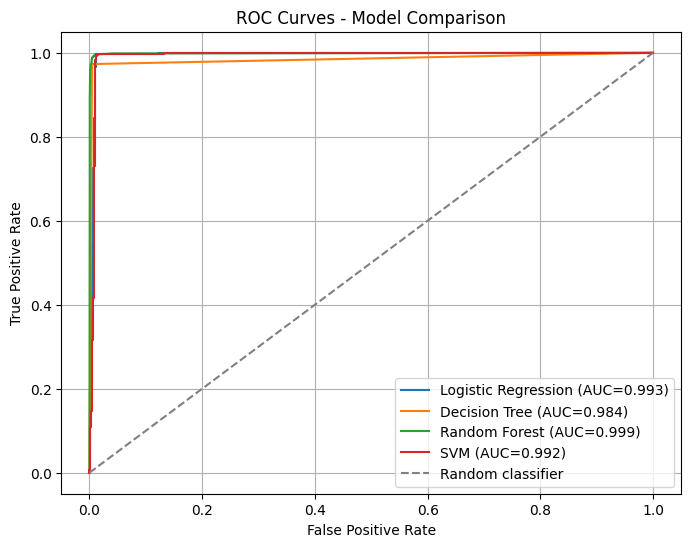

In [ ]:
plt.figure(figsize=(8, 6))

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC={roc_auc_score(y_test, y_prob):.3f})")

for name, model in fitted_models.items():
    y_prob_model = model.predict_proba(X_test)[:, 1]
    fpr_m, tpr_m, _ = roc_curve(y_test, y_prob_model)
    plt.plot(fpr_m, tpr_m, label=f"{name} (AUC={roc_auc_score(y_test, y_prob_model):.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Model Comparison")
plt.legend()
plt.grid(True)
plt.show()

## 24. Reducerea numărului de senzori în ordinea relevanței

Pot obține performanță bună cu mai puțini senzori?

Folosesc combinații logice bazate pe corelația cu `Occupancy`:
1. doar Light;
2. Light + Temperature;
3. Light + Temperature + CO2;
4. Light + Temperature + CO2 + HumidityRatio;
5. toți cei 5 senzori.

Această analiză este importantă pentru robotică deoarece mai puțini senzori înseamnă:
- cost mai mic;
- complexitate mai mică;
- consum mai mic;
- implementare mai simplă.

In [ ]:
# Definim seturile de senzori testate.
feature_sets = {
    "1 sensor: Light": ["Light"],
    "2 sensors: Light + Temperature": ["Light", "Temperature"],
    "3 sensors: Light + Temperature + CO2": ["Light", "Temperature", "CO2"],
    "4 sensors: Light + Temperature + CO2 + HumidityRatio": ["Light", "Temperature", "CO2", "HumidityRatio"],
    "5 sensors: All features": ["Light", "Temperature", "CO2", "HumidityRatio", "Humidity"]
}

# Inițializăm lista pentru rezultate.
sensor_results = []

# Parcurgem fiecare set de senzori.
for model_name, features in feature_sets.items():

    # Selectăm doar senzorii din setul curent.
    X_subset = df_clean[features]

    # Target-ul rămâne același.
    y_subset = df_clean[target]

    # Împărțim datele în train și test.
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X_subset,
        y_subset,
        test_size=0.25,
        random_state=42,
        stratify=y_subset
    )

    # Construim modelul Logistic Regression.
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(max_iter=1000))
    ])

    # Antrenăm modelul.
    model.fit(X_train_s, y_train_s)

    # Calculăm predicțiile.
    y_pred_s = model.predict(X_test_s)

    # Calculăm probabilitățile pentru clasa ocupat.
    y_prob_s = model.predict_proba(X_test_s)[:, 1]

    # Salvăm rezultatele.
    sensor_results.append({
        "Model": model_name,
        "Sensors Used": len(features),
        "Features": ", ".join(features),
        "Accuracy": accuracy_score(y_test_s, y_pred_s),
        "Precision": precision_score(y_test_s, y_pred_s),
        "Recall": recall_score(y_test_s, y_pred_s),
        "F1-score": f1_score(y_test_s, y_pred_s),
        "ROC-AUC": roc_auc_score(y_test_s, y_prob_s)
    })

# Transformăm rezultatele în DataFrame.
sensor_results_df = pd.DataFrame(sensor_results)

# Afișăm tabelul.
sensor_results_df

,Model,Sensors Used,Features,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,1 sensor: Light,1,Light,0.985992,0.947073,0.994945,0.970419,0.992368
1,2 sensors: Light + Temperature,2,"Light, Temperature",0.988521,0.957050,0.994945,0.975630,0.991329
2,3 sensors: Light + Temperature + CO2,3,"Light, Temperature, CO2",0.988911,0.959350,0.994103,0.976417,0.992778
3,4 sensors: Light + Temperature + CO2 + Humidit...,4,"Light, Temperature, CO2, HumidityRatio",0.988911,0.959350,0.994103,0.976417,0.993329
4,5 sensors: All features,5,"Light, Temperature, CO2, HumidityRatio, Humidity",0.988911,0.959350,0.994103,0.976417,0.993328


## 25. Grafic: performanță în funcție de numărul de senzori

Acest grafic arată dacă performanța crește semnificativ atunci când adaug mai mulți senzori.

Dacă performanța cu 3 senzori este aproape la fel ca performanța cu 5 senzori, pot argumenta că modelul poate fi simplificat.

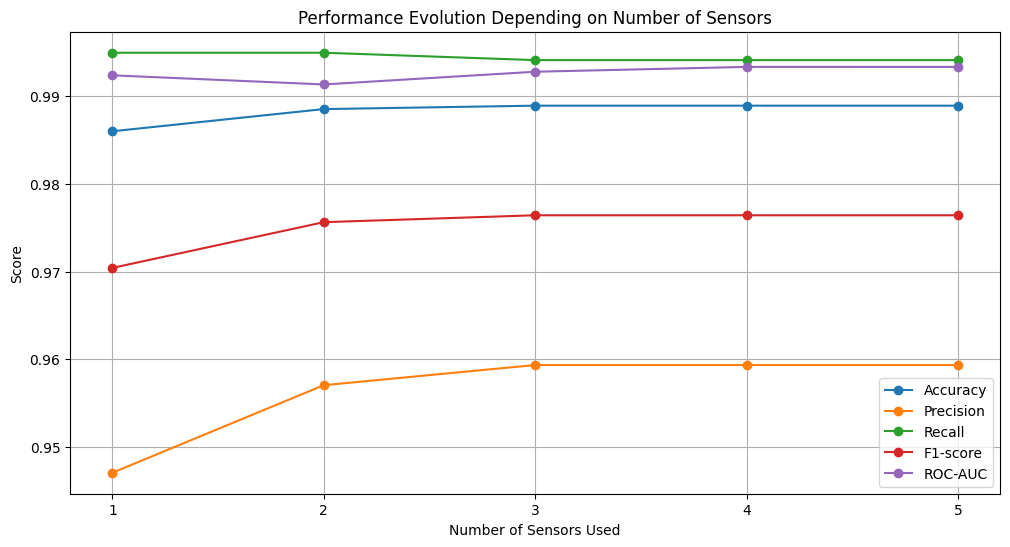

In [ ]:
# Definim metricile pe care vrem să le afișăm.
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

# Setăm dimensiunea figurii.
plt.figure(figsize=(12, 6))

# Desenăm câte o linie pentru fiecare metrică.
for metric in metrics:
    plt.plot(
        sensor_results_df["Sensors Used"],
        sensor_results_df[metric],
        marker="o",
        label=metric
    )

# Eticheta axei X.
plt.xlabel("Number of Sensors Used")

# Eticheta axei Y.
plt.ylabel("Score")

# Titlul graficului.
plt.title("Performance Evolution Depending on Number of Sensors")

# Afișăm valorile întregi pe axa X.
plt.xticks(sensor_results_df["Sensors Used"])

# Afișăm legenda.
plt.legend()

# Adăugăm grid.
plt.grid(True)

# Afișăm graficul.
plt.show()

## 26. Toate combinațiile de senzori

Testez toate combinațiile posibile de senzori.

Scopul este să vad:
- care combinație are cea mai bună performanță;
- dacă pot obține rezultate foarte bune cu un număr redus de senzori.

In [ ]:
# Inițializăm lista pentru rezultatele ablation study.
ablation_results = []

# Testăm combinații cu 1, 2, 3, 4 și 5 senzori.
for r in range(1, len(all_features) + 1):

    # Generăm toate combinațiile posibile de r senzori.
    for feature_subset in combinations(all_features, r):

        # Transformăm combinația în listă.
        feature_subset = list(feature_subset)

        # Selectăm datele pentru combinația curentă.
        X_subset = df_clean[feature_subset]

        # Target-ul rămâne Occupancy.
        y_subset = df_clean[target]

        # Împărțim datele în train și test.
        X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
            X_subset,
            y_subset,
            test_size=0.25,
            random_state=42,
            stratify=y_subset
        )

        # Construim modelul.
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("lr", LogisticRegression(max_iter=1000))
        ])

        # Antrenăm modelul.
        model.fit(X_train_a, y_train_a)

        # Calculăm predicțiile.
        y_pred_a = model.predict(X_test_a)

        # Calculăm probabilitățile.
        y_prob_a = model.predict_proba(X_test_a)[:, 1]

        # Salvăm rezultatele.
        ablation_results.append({
            "Number of Sensors": len(feature_subset),
            "Sensors": ", ".join(feature_subset),
            "Accuracy": accuracy_score(y_test_a, y_pred_a),
            "Precision": precision_score(y_test_a, y_pred_a),
            "Recall": recall_score(y_test_a, y_pred_a),
            "F1-score": f1_score(y_test_a, y_pred_a),
            "ROC-AUC": roc_auc_score(y_test_a, y_prob_a)
        })

# Transformăm rezultatele în DataFrame.
ablation_df = pd.DataFrame(ablation_results)

# Sortăm rezultatele după ROC-AUC descrescător și apoi după numărul de senzori crescător.
ablation_df = ablation_df.sort_values(
    by=["ROC-AUC", "Number of Sensors"],
    ascending=[False, True]
)

# Afișăm cele mai bune 15 combinații.
ablation_df.head(15)

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Number of Sensors,Sensors,Accuracy,Precision,Recall,F1-score,ROC-AUC
21,3,"Humidity, Light, CO2",0.988716,0.958570,0.994103,0.976013,0.993757
24,3,"Light, CO2, HumidityRatio",0.988716,0.958570,0.994103,0.976013,0.993639
12,2,"Light, CO2",0.988911,0.959350,0.994103,0.976417,0.993524
29,4,"Humidity, Light, CO2, HumidityRatio",0.988911,0.959350,0.994103,0.976417,0.993387
9,2,"Humidity, Light",0.987549,0.953921,0.994103,0.973597,0.993372
28,4,"Temperature, Light, CO2, HumidityRatio",0.988911,0.959350,0.994103,0.976417,0.993329
30,5,"Temperature, Humidity, Light, CO2, HumidityRatio",0.988911,0.959350,0.994103,0.976417,0.993328
25,4,"Temperature, Humidity, Light, CO2",0.988911,0.959350,0.994103,0.976417,0.993317
13,2,"Light, HumidityRatio",0.987743,0.954693,0.994103,0.973999,0.993262
22,3,"Humidity, Light, HumidityRatio",0.987938,0.955466,0.994103,0.974401,0.992907


## 27. Alegerea celui mai simplu model aproape la fel de bun ca modelul maxim

În practică, nu se alege mereu modelul cu scorul maxim absolut.

Pentru robotică, poate fi mai bine să alegem un model cu mai puțini senzori, dacă performanța este aproape identică.

Selectez modelele care sunt la maximum `0.005` ROC-AUC sub cel mai bun rezultat.

In [ ]:
# Identificăm cel mai bun ROC-AUC obținut dintre toate combinațiile.
best_roc = ablation_df["ROC-AUC"].max()

# Afișăm valoarea maximă ROC-AUC.
print("Best ROC-AUC obtained:", round(best_roc, 6))

# Selectăm modelele cu performanță foarte apropiată de cea mai bună.
best_simple_models = ablation_df[
    ablation_df["ROC-AUC"] >= best_roc - 0.005
].sort_values(
    by=["ROC-AUC", "Number of Sensors"],
    ascending=[False, True]
)

# Afișăm modelele.
best_simple_models

Best ROC-AUC obtained: 0.993757


,Number of Sensors,Sensors,Accuracy,Precision,Recall,F1-score,ROC-AUC
21,3,"Humidity, Light, CO2",0.988716,0.958570,0.994103,0.976013,0.993757
24,3,"Light, CO2, HumidityRatio",0.988716,0.958570,0.994103,0.976013,0.993639
12,2,"Light, CO2",0.988911,0.959350,0.994103,0.976417,0.993524
29,4,"Humidity, Light, CO2, HumidityRatio",0.988911,0.959350,0.994103,0.976417,0.993387
9,2,"Humidity, Light",0.987549,0.953921,0.994103,0.973597,0.993372
28,4,"Temperature, Light, CO2, HumidityRatio",0.988911,0.959350,0.994103,0.976417,0.993329
30,5,"Temperature, Humidity, Light, CO2, HumidityRatio",0.988911,0.959350,0.994103,0.976417,0.993328
25,4,"Temperature, Humidity, Light, CO2",0.988911,0.959350,0.994103,0.976417,0.993317
13,2,"Light, HumidityRatio",0.987743,0.954693,0.994103,0.973999,0.993262
22,3,"Humidity, Light, HumidityRatio",0.987938,0.955466,0.994103,0.974401,0.992907


## 28. Analiza pragului de clasificare

Implicit, Logistic Regression folosește pragul `0.5`:
- probabilitate >= 0.5 → Occupancy = 1;
- probabilitate < 0.5 → Occupancy = 0.

Dar în robotică, pragul poate fi schimbat în funcție de obiectiv:
- mai multă siguranță;
- mai puține false negatives;
- echilibru între precision și recall.

In [ ]:
# Definim praguri între 0.10 și 0.90.
thresholds = np.arange(0.10, 0.91, 0.01)

# Inițializăm lista pentru rezultate.
threshold_results = []

# Testăm fiecare prag.
for threshold in thresholds:

    # Transformăm probabilitățile în predicții folosind pragul curent.
    y_pred_threshold = (y_prob >= threshold).astype(int)

    # Salvăm metricile pentru pragul curent.
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision": precision_score(y_test, y_pred_threshold),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1-score": f1_score(y_test, y_pred_threshold)
    })

# Transformăm rezultatele în DataFrame.
threshold_df = pd.DataFrame(threshold_results)

# Afișăm primele rânduri.
threshold_df.head()

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.10,0.983074,0.934439,0.996630,0.964533
1,0.11,0.984241,0.938889,0.996630,0.966898
2,0.12,0.985019,0.942584,0.995788,0.968456
3,0.13,0.985603,0.944844,0.995788,0.969647
4,0.14,0.985992,0.946357,0.995788,0.970443


## 34. Sistem robotic de decizie pe trei niveluri

În loc să folosesc doar decizia binară:
- liber;
- ocupat;

transform probabilitatea într-o acțiune robotică:
- `MOVE / SAFE`;
- `SLOW DOWN / CAUTION`;
- `STOP / OCCUPIED AREA`.



In [ ]:
# Definim funcția de decizie robotică.
def decision_system(probability):

    # Dacă probabilitatea este sub 0.40, mediul este considerat sigur.
    if probability < 0.40:
        return "MOVE / SAFE"

    # Dacă probabilitatea este între 0.40 și 0.70, robotul trebuie să fie precaut.
    elif probability < 0.70:
        return "SLOW DOWN / CAUTION"

    # Dacă probabilitatea este peste 0.70, mediul este considerat ocupat sau riscant.
    else:
        return "STOP / OCCUPIED AREA"

## 35. Aplicarea sistemului de decizie

Aplic funcția `decision_system()` pe probabilitățile produse de Logistic Regression.

Rezultatul este o listă de acțiuni robotice.

In [ ]:
# Aplicăm sistemul de decizie pentru fiecare probabilitate prezisă.
robotic_decisions = [
    decision_system(probability)
    for probability in y_prob
]

# Construim un tabel cu probabilitatea, decizia și valoarea reală.
decision_df = pd.DataFrame({
    "Predicted Probability": y_prob,
    "Robotic Decision": robotic_decisions,
    "Real Occupancy": y_test.values
})

# Afișăm primele 20 de decizii.
decision_df.head(20)

,Predicted Probability,Robotic Decision,Real Occupancy
0,0.000195,MOVE / SAFE,0
1,0.000942,MOVE / SAFE,0
2,0.000118,MOVE / SAFE,0
3,0.000140,MOVE / SAFE,0
4,0.000105,MOVE / SAFE,0
5,0.011243,MOVE / SAFE,0
6,0.000162,MOVE / SAFE,0
7,0.000754,MOVE / SAFE,0
8,0.105836,MOVE / SAFE,0
9,0.000467,MOVE / SAFE,0


## 36. Distribuția deciziilor robotice

Această celulă arată câte cazuri au dus la:
- MOVE;
- SLOW DOWN;
- STOP.

Robotic Decision
MOVE / SAFE             3906
STOP / OCCUPIED AREA    1223
SLOW DOWN / CAUTION       11
Name: count, dtype: int64


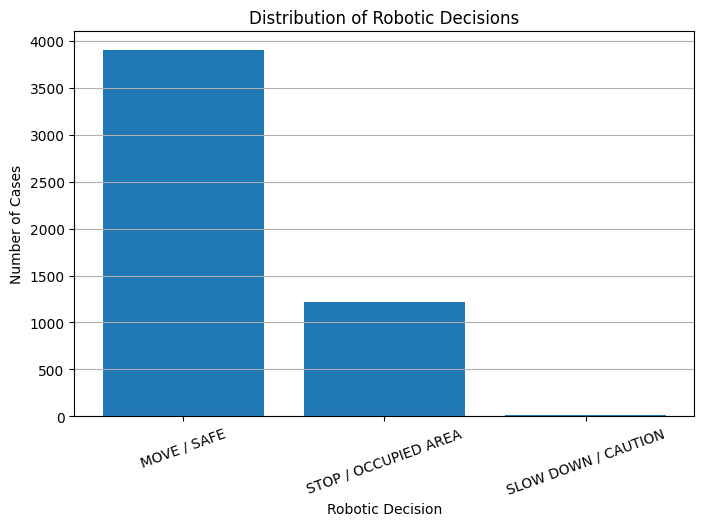

In [ ]:
# Numărăm deciziile robotice.
decision_counts = decision_df["Robotic Decision"].value_counts()

# Afișăm numărul de apariții pentru fiecare decizie.
print(decision_counts)

# Setăm dimensiunea figurii.
plt.figure(figsize=(8, 5))

# Desenăm distribuția deciziilor.
plt.bar(
    decision_counts.index,
    decision_counts.values
)

# Eticheta axei X.
plt.xlabel("Robotic Decision")

# Eticheta axei Y.
plt.ylabel("Number of Cases")

# Titlul graficului.
plt.title("Distribution of Robotic Decisions")

# Rotim etichetele.
plt.xticks(rotation=20)

# Adăugăm grid.
plt.grid(axis="y")

# Afișăm graficul.
plt.show()

## 36. Simulare pseudo-real-time

Această simulare ia primele 50 de exemple din setul de test și le tratează ca pe o secvență de citiri de senzori.

Pentru fiecare pas:
- modelul produce probabilitatea de ocupare;
- sistemul produce o decizie robotică.

In [ ]:
# Copiem primele 50 de rânduri din tabelul de decizii.
simulation_df = decision_df.head(50).copy()

# Adăugăm o coloană Step pentru a simula timpul.
simulation_df["Step"] = range(1, len(simulation_df) + 1)

# Afișăm simularea.
simulation_df

,Predicted Probability,Robotic Decision,Real Occupancy,Step
0,0.000195,MOVE / SAFE,0,1
1,0.000942,MOVE / SAFE,0,2
2,0.000118,MOVE / SAFE,0,3
3,0.000140,MOVE / SAFE,0,4
4,0.000105,MOVE / SAFE,0,5
5,0.011243,MOVE / SAFE,0,6
6,0.000162,MOVE / SAFE,0,7
7,0.000754,MOVE / SAFE,0,8
8,0.105836,MOVE / SAFE,0,9
9,0.000467,MOVE / SAFE,0,10


## 37. Simulare interactivă validată pentru robot

Modul de testare manuală: utilizatorul introduce valori pentru cei 5 senzori, iar sistemul acceptă doar valori aflate în intervalele reale observate în dataset, apoi calculează probabilitatea de ocupare și decizia robotică corespunzătoare.

In [ ]:
# ============================================================
# SIMULARE INTERACTIVĂ VALIDATĂ PENTRU ROBOT
# Acceptă doar valori aflate în intervalele reale din dataset.
# ============================================================

features = ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']


# ============================================================
# 1. INTERVALE REALE DIN DATASET
# ============================================================

ranges = {}

print("INTERVALE ACCEPTATE DIN DATASET")
print("-" * 70)

for feature in features:
    min_value = df_clean[feature].min()
    max_value = df_clean[feature].max()

    ranges[feature] = {
        "min": min_value,
        "max": max_value
    }

    print(
        f"{feature}: "
        f"{round(min_value, 2)} - {round(max_value, 2)}"
    )


# ============================================================
# 2. FUNCȚIE CARE ACCEPTĂ DOAR VALORI CORECTE
# ============================================================

def read_valid_sensor_value(feature_name):

    min_value = ranges[feature_name]["min"]
    max_value = ranges[feature_name]["max"]

    while True:
        try:
            value = float(
                input(
                    f"Introdu valoarea pentru {feature_name} "
                    f"[{round(min_value, 2)} - {round(max_value, 2)}]: "
                )
            )

            if value < min_value or value > max_value:
                print(
                    f"Valoare invalidă. Pentru {feature_name}, "
                    f"introdu o valoare între "
                    f"{round(min_value, 2)} și {round(max_value, 2)}."
                )
            else:
                return value

        except ValueError:
            print("Valoare invalidă. Introdu un număr.")


# ============================================================
# 3. CITIREA VALORILOR DE LA UTILIZATOR
# ============================================================

temperature_value = read_valid_sensor_value('Temperature')
humidity_value = read_valid_sensor_value('Humidity')
light_value = read_valid_sensor_value('Light')
co2_value = read_valid_sensor_value('CO2')
humidity_ratio_value = read_valid_sensor_value('HumidityRatio')


# ============================================================
# 4. CONSTRUIM EXEMPLUL INTRODUS
# ============================================================

manual_input = pd.DataFrame({
    'Temperature': [temperature_value],
    'Humidity': [humidity_value],
    'Light': [light_value],
    'CO2': [co2_value],
    'HumidityRatio': [humidity_ratio_value]
})

print("\nVALORI INTRODUSE:")
display(manual_input)


# ============================================================
# 5. PREDICȚIA MODELULUI
# ============================================================

probability_occupied = model.predict_proba(
    manual_input[features]
)[:, 1][0]


# ============================================================
# 6. DECIZIA ROBOTULUI
# ============================================================

if probability_occupied < 0.40:
    robot_decision = "ROBOTUL ÎNAINTEAZĂ"

elif probability_occupied < 0.70:
    robot_decision = "ROBOTUL ÎNCETINEȘTE"

else:
    robot_decision = "ROBOTUL SE OPREȘTE"


# ============================================================
# 7. REZULTAT FINAL
# ============================================================

print("\nREZULTATUL SIMULĂRII")
print("-" * 70)

print("Probabilitate ocupare:", round(probability_occupied, 2))
print("Decizie robot:", robot_decision)


# ============================================================
# 8. INTERPRETARE
# ============================================================

if probability_occupied < 0.40:
    print("""
Camera pare liberă.
Robotul își poate continua deplasarea.
""")

elif probability_occupied < 0.70:
    print("""
Situația este incertă.
Robotul trebuie să încetinească.
""")

else:
    print("""
Camera pare ocupată.
Robotul trebuie să se oprească.
""")


# ============================================================
# 9. EXPLICAȚIE SPECIALĂ PENTRU LUMINĂ
# ============================================================

print("\nANALIZA LUMINII")
print("-" * 70)

if light_value == 0:
    print("""
Light = 0.
Nu există lumină detectată.
În acest caz, robotul trebuie să se bazeze și pe ceilalți senzori.
""")

elif light_value < 100:
    print("""
Lumina este foarte slabă.
Poate fi apus, răsărit sau lumină ambientală redusă.
""")

elif light_value < 300:
    print("""
Lumina este într-o zonă incertă.
Robotul trebuie să interpreteze și CO2, temperatura și umiditatea.
""")

else:
    print("""
Lumina este ridicată.
În dataset, acest lucru este frecvent asociat cu o cameră ocupată.
""")

INTERVALE ACCEPTATE DIN DATASET
----------------------------------------------------------------------
Temperature: 19.0 - 24.41
Humidity: 16.75 - 39.5
Light: 0.0 - 1697.25
CO2: 412.75 - 2076.5
HumidityRatio: 0.0 - 0.01
Introdu valoarea pentru Temperature [19.0 - 24.41]: 19
Introdu valoarea pentru Humidity [16.75 - 39.5]: 17
Introdu valoarea pentru Light [0.0 - 1697.25]: 500
Introdu valoarea pentru CO2 [412.75 - 2076.5]: 500
Introdu valoarea pentru HumidityRatio [0.0 - 0.01]: 0.003

VALORI INTRODUSE:


,Temperature,Humidity,Light,CO2,HumidityRatio
0,19.0,17.0,500.0,500.0,0.003



REZULTATUL SIMULĂRII
----------------------------------------------------------------------
Probabilitate ocupare: 1.0
Decizie robot: ROBOTUL SE OPREȘTE

Camera pare ocupată.
Robotul trebuie să se oprească.


ANALIZA LUMINII
----------------------------------------------------------------------

Lumina este ridicată.
În dataset, acest lucru este frecvent asociat cu o cameră ocupată.



## 39. Analiză specială pentru variabila `Light`



Aici analizez:

- câte valori de lumină sunt zero;
- care este rata de ocupare când lumina este zero;
- cum se comportă ocuparea pe intervale de lumină;
- ce se întâmplă în zona incertă, de exemplu apus, răsărit sau zile de iarnă.

In [ ]:
# Calculăm quartilele pentru variabila Light.
light_quantiles = df_clean["Light"].quantile([0, 0.25, 0.50, 0.75, 1.0])

# Afișăm quartilele pentru Light.
print("Quartile pentru Light:")
print(light_quantiles)

# Numărăm câte exemple au Light egal cu 0.
no_light_count = (df_clean["Light"] == 0).sum()

# Calculăm procentul exemplelor cu Light egal cu 0.
no_light_percent = no_light_count / len(df_clean) * 100

# Afișăm numărul de cazuri cu Light egal cu 0.
print("\nNumăr cazuri cu Light = 0:", no_light_count)

# Afișăm procentul de cazuri cu Light egal cu 0.
print("Procent cazuri cu Light = 0:", round(no_light_percent, 2), "%")

# Construim categorii manuale pentru Light, deoarece qcut poate eșua când există multe valori identice de 0.
df_clean["Light_Category"] = pd.cut(
    # Folosim coloana Light pentru împărțire pe intervale.
    df_clean["Light"],

    # Definim intervalele: fără lumină, lumină slabă/incertă, lumină ridicată.
    bins=[-1, 0, 301, df_clean["Light"].max()],

    # Definim numele categoriilor.
    labels=["no_light", "low_or_uncertain_light", "high_light"],

    # Includem limita inferioară în primul interval.
    include_lowest=True
)

# Grupăm datele după categoria de lumină.
light_analysis = df_clean.groupby("Light_Category", observed=False).agg(
    # Numărăm câte exemple există în fiecare categorie.
    count=("Occupancy", "count"),

    # Calculăm rata medie de ocupare pentru fiecare categorie.
    occupancy_rate=("Occupancy", "mean"),

    # Calculăm valoarea minimă a luminii în fiecare categorie.
    light_min=("Light", "min"),

    # Calculăm valoarea maximă a luminii în fiecare categorie.
    light_max=("Light", "max"),

    # Calculăm media luminii în fiecare categorie.
    light_mean=("Light", "mean")
).reset_index()

# Transformăm rata de ocupare în procent.
light_analysis["occupancy_rate_percent"] = (light_analysis["occupancy_rate"] * 100).round(2)

# Afișăm analiza pe categorii de lumină.
light_analysis

Quartile pentru Light:
0.00       0.00
0.25       0.00
0.50       0.00
0.75     301.00
1.00    1697.25
Name: Light, dtype: float64

Număr cazuri cu Light = 0: 12772
Procent cazuri cu Light = 0: 62.12 %


,Light_Category,count,occupancy_rate,light_min,light_max,light_mean,occupancy_rate_percent
0,no_light,12772,0.000078,0.000000,0.00,0.000000,0.01
1,low_or_uncertain_light,2651,0.005658,4.666667,301.00,88.692744,0.57
2,high_light,5137,0.921550,302.000000,1697.25,477.561162,92.15


## 40. Model doar cu `Light` versus model fără `Light`

Dacă nu există lumină, ce valori obțin?


Aici compar două scenarii importante:

1. **Model doar cu Light**  
   Verific dacă o singură variabilă este suficientă.

2. **Model fără Light**  
   Verific ce se întâmplă dacă senzorul de lumină nu există sau nu poate fi folosit.



In [ ]:
# Definim lista de variabile pentru modelul care folosește doar Light.
only_light_features = ["Light"]

# Definim lista de variabile pentru modelul care exclude Light.
without_light_features = ["Temperature", "Humidity", "CO2", "HumidityRatio"]

# Inițializăm o listă pentru rezultatele comparației.
light_comparison_results = []

# Definim un dicționar cu cele două scenarii pe care vrem să le testăm.
light_scenarios = {
    # Primul scenariu folosește doar variabila Light.
    "Only Light": only_light_features,

    # Al doilea scenariu folosește toate variabilele în afară de Light.
    "Without Light": without_light_features
}

# Parcurgem fiecare scenariu definit mai sus.
for scenario_name, scenario_features in light_scenarios.items():

    # Selectăm variabilele de intrare pentru scenariul curent.
    X_scenario = df_clean[scenario_features]

    # Selectăm variabila țintă.
    y_scenario = df_clean[target]

    # Împărțim datele în train și test pentru scenariul curent.
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        # Datele de intrare.
        X_scenario,

        # Clasele reale.
        y_scenario,

        # Folosim 25% din date pentru testare.
        test_size=0.25,

        # Fixăm random_state pentru rezultate reproductibile.
        random_state=42,

        # Păstrăm proporția claselor în train și test.
        stratify=y_scenario
    )

    # Construim pipeline-ul cu standardizare și logistic regression.
    scenario_model = Pipeline([
        # Standardizăm variabilele.
        ("scaler", StandardScaler()),

        # Antrenăm modelul Logistic Regression.
        ("lr", LogisticRegression(max_iter=1000))
    ])

    # Măsurăm timpul înainte de antrenare.
    start_train_time = time.time()

    # Antrenăm modelul pe datele de train.
    scenario_model.fit(X_train_s, y_train_s)

    # Calculăm timpul de antrenare.
    train_time = time.time() - start_train_time

    # Măsurăm timpul înainte de predicție.
    start_pred_time = time.time()

    # Calculăm predicțiile binare.
    y_pred_s = scenario_model.predict(X_test_s)

    # Calculăm probabilitatea pentru clasa 1.
    y_prob_s = scenario_model.predict_proba(X_test_s)[:, 1]

    # Calculăm timpul de predicție.
    pred_time = time.time() - start_pred_time

    # Adăugăm rezultatele scenariului curent în listă.
    light_comparison_results.append({
        # Salvăm numele scenariului.
        "Scenario": scenario_name,

        # Salvăm variabilele folosite.
        "Features": ", ".join(scenario_features),

        # Salvăm numărul de variabile folosite.
        "Number of Features": len(scenario_features),

        # Calculăm accuracy.
        "Accuracy": accuracy_score(y_test_s, y_pred_s),

        # Calculăm precision.
        "Precision": precision_score(y_test_s, y_pred_s),

        # Calculăm recall.
        "Recall": recall_score(y_test_s, y_pred_s),

        # Calculăm F1-score.
        "F1-score": f1_score(y_test_s, y_pred_s),

        # Calculăm ROC-AUC.
        "ROC-AUC": roc_auc_score(y_test_s, y_prob_s),

        # Salvăm timpul de antrenare.
        "Training Time": train_time,

        # Salvăm timpul de predicție.
        "Prediction Time": pred_time
    })

    # Salvăm modelul doar cu Light pentru analize ulterioare.
    if scenario_name == "Only Light":
        # Reținem modelul doar cu Light.
        only_light_model = scenario_model

        # Reținem setul de test pentru modelul doar cu Light.
        X_test_only_light = X_test_s

        # Reținem clasele reale pentru modelul doar cu Light.
        y_test_only_light = y_test_s

    # Salvăm modelul fără Light pentru analize ulterioare.
    if scenario_name == "Without Light":
        # Reținem modelul fără Light.
        without_light_model = scenario_model

        # Reținem setul de test pentru modelul fără Light.
        X_test_without_light = X_test_s

        # Reținem clasele reale pentru modelul fără Light.
        y_test_without_light = y_test_s

# Transformăm lista de rezultate într-un DataFrame.
light_comparison_df = pd.DataFrame(light_comparison_results)

# Rotunjim valorile numerice pentru afișare.
light_comparison_df = light_comparison_df.round(4)

# Afișăm comparația dintre modelul doar cu Light și modelul fără Light.
light_comparison_df

,Scenario,Features,Number of Features,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time,Prediction Time
0,Only Light,Light,1,0.9860,0.9471,0.9949,0.9704,0.9924,0.0471,0.0042
1,Without Light,"Temperature, Humidity, CO2, HumidityRatio",4,0.8226,0.6387,0.5333,0.5813,0.9049,0.0414,0.0044


## 41. Ce se întâmplă când `Light = 0`

Această analiză arată ce predicții produce modelul pentru cazurile în care nu există lumină sau lumina este stinsă.

Este important pentru scenarii precum:
- cameră întunecată;
- noapte;
- senzor de lumină care indică valoare zero;
- robot care intră într-o zonă fără iluminare.

In [ ]:
# Selectăm cazurile în care Light este exact 0.
no_light_df = df_clean[df_clean["Light"] == 0].copy()

# Afișăm câte cazuri avem cu Light egal cu 0.
print("Număr cazuri cu Light = 0:", len(no_light_df))

# Verificăm dacă există cazuri cu Light egal cu 0.
if len(no_light_df) > 0:

    # Calculăm probabilitatea de ocupare folosind modelul doar cu Light.
    no_light_df["prob_only_light"] = only_light_model.predict_proba(no_light_df[only_light_features])[:, 1]

    # Transformăm probabilitatea în decizie robotică.
    no_light_df["decision_only_light"] = no_light_df["prob_only_light"].apply(decision_system)

    # Calculăm probabilitatea de ocupare folosind modelul fără Light.
    no_light_df["prob_without_light"] = without_light_model.predict_proba(no_light_df[without_light_features])[:, 1]

    # Transformăm probabilitatea în decizie robotică.
    no_light_df["decision_without_light"] = no_light_df["prob_without_light"].apply(decision_system)

    # Selectăm coloanele importante pentru interpretare.
    no_light_comparison = no_light_df[
        [
            "Temperature",
            "Humidity",
            "Light",
            "CO2",
            "HumidityRatio",
            "Occupancy",
            "prob_only_light",
            "decision_only_light",
            "prob_without_light",
            "decision_without_light"
        ]
    ].copy()

    # Rotunjim probabilitățile pentru afișare.
    no_light_comparison[["prob_only_light", "prob_without_light"]] = no_light_comparison[
        ["prob_only_light", "prob_without_light"]
    ].round(4)

    # Afișăm primele 20 de cazuri cu Light egal cu 0.
    display(no_light_comparison.head(20))

    # Grupăm deciziile pentru modelul doar cu Light.
    print("\nDistribuția deciziilor pentru modelul doar cu Light:")
    print(no_light_df["decision_only_light"].value_counts())

    # Grupăm deciziile pentru modelul fără Light.
    print("\nDistribuția deciziilor pentru modelul fără Light:")
    print(no_light_df["decision_without_light"].value_counts())

# Dacă nu există cazuri cu Light egal cu 0, afișăm un mesaj clar.
else:
    # Mesaj pentru cazul fără date.
    print("Nu există cazuri cu Light = 0 în dataset.")

Număr cazuri cu Light = 0: 12772


,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy,prob_only_light,decision_only_light,prob_without_light,decision_without_light
217,21.700000,28.566667,0.0,582.000000,0.004587,0,0.0001,MOVE / SAFE,0.2468,MOVE / SAFE
218,21.700000,28.760000,0.0,578.000000,0.004618,0,0.0001,MOVE / SAFE,0.2456,MOVE / SAFE
219,21.700000,28.790000,0.0,584.000000,0.004623,0,0.0001,MOVE / SAFE,0.2488,MOVE / SAFE
220,21.700000,28.790000,0.0,586.500000,0.004623,0,0.0001,MOVE / SAFE,0.2500,MOVE / SAFE
221,21.700000,28.840000,0.0,587.500000,0.004631,0,0.0001,MOVE / SAFE,0.2508,MOVE / SAFE
222,21.700000,28.860000,0.0,586.000000,0.004634,0,0.0001,MOVE / SAFE,0.2501,MOVE / SAFE
223,21.700000,28.860000,0.0,592.333333,0.004634,0,0.0001,MOVE / SAFE,0.2533,MOVE / SAFE
224,21.700000,28.790000,0.0,590.000000,0.004623,0,0.0001,MOVE / SAFE,0.2518,MOVE / SAFE
225,21.600000,28.895000,0.0,590.000000,0.004612,0,0.0001,MOVE / SAFE,0.2260,MOVE / SAFE
226,21.633333,28.790000,0.0,590.500000,0.004604,0,0.0001,MOVE / SAFE,0.2344,MOVE / SAFE



Distribuția deciziilor pentru modelul doar cu Light:
decision_only_light
MOVE / SAFE    12772
Name: count, dtype: int64

Distribuția deciziilor pentru modelul fără Light:
decision_without_light
MOVE / SAFE             11853
SLOW DOWN / CAUTION       781
STOP / OCCUPIED AREA      138
Name: count, dtype: int64


## 42. Cazuri cu lumină incertă: apus, răsărit, iarnă

În dataset, lumina poate avea multe valori egale cu zero, deci împărțirea automată în quartile poate eșua.

De aceea folosesc o regulă manuală:

- `Light = 0` → fără lumină;
- `0 < Light <= 301` → lumină slabă sau incertă;
- `Light > 301` → lumină ridicată.

Zona `0 < Light <= 301` poate aproxima situații precum:
- apus;
- răsărit;
- zile de iarnă când se întunecă devreme;
- lumină naturală slabă;
- cameră parțial iluminată.

In [ ]:
# Selectăm cazurile cu lumină slabă sau incertă.
uncertain_light_df = df_clean[
    # Condiția Light > 0 exclude întunericul complet.
    (df_clean["Light"] > 0) &

    # Condiția Light <= 301 păstrează zona slabă/incertă.
    (df_clean["Light"] <= 301)
].copy()

# Afișăm câte cazuri există în zona de lumină incertă.
print("Număr cazuri cu lumină incertă:", len(uncertain_light_df))

# Verificăm dacă există date în zona de lumină incertă.
if len(uncertain_light_df) > 0:

    # Alegem un eșantion de maximum 20 de exemple pentru afișare.
    sample_uncertain = uncertain_light_df.sample(
        # Alegem minimum dintre 20 și numărul total de exemple disponibile.
        min(20, len(uncertain_light_df)),

        # Fixăm random_state pentru rezultate reproductibile.
        random_state=42
    ).copy()

    # Calculăm probabilitatea de ocupare folosind modelul doar cu Light.
    sample_uncertain["prob_only_light"] = only_light_model.predict_proba(sample_uncertain[only_light_features])[:, 1]

    # Transformăm probabilitatea în decizie robotică pentru modelul doar cu Light.
    sample_uncertain["decision_only_light"] = sample_uncertain["prob_only_light"].apply(decision_system)

    # Calculăm probabilitatea de ocupare folosind modelul fără Light.
    sample_uncertain["prob_without_light"] = without_light_model.predict_proba(sample_uncertain[without_light_features])[:, 1]

    # Transformăm probabilitatea în decizie robotică pentru modelul fără Light.
    sample_uncertain["decision_without_light"] = sample_uncertain["prob_without_light"].apply(decision_system)

    # Selectăm coloanele importante pentru comparație.
    comparison_uncertain = sample_uncertain[
        [
            "Temperature",
            "Humidity",
            "Light",
            "CO2",
            "HumidityRatio",
            "Occupancy",
            "prob_only_light",
            "decision_only_light",
            "prob_without_light",
            "decision_without_light"
        ]
    ].copy()

    # Rotunjim probabilitățile pentru afișare.
    comparison_uncertain[["prob_only_light", "prob_without_light"]] = comparison_uncertain[
        ["prob_only_light", "prob_without_light"]
    ].round(4)

    # Afișăm comparația pentru cazurile cu lumină incertă.
    display(comparison_uncertain)

# Dacă nu există date în zona aleasă, afișăm un mesaj clar.
else:
    # Mesaj pentru cazul fără date.
    print("Nu există cazuri în intervalul 0 < Light <= 301. Verifică distribuția variabilei Light.")

Număr cazuri cu lumină incertă: 2651


,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy,prob_only_light,decision_only_light,prob_without_light,decision_without_light
18011,20.245000,26.245000,54.500000,425.250000,0.003849,0,0.0004,MOVE / SAFE,0.0333,MOVE / SAFE
1369,24.200000,23.815000,182.500000,688.750000,0.004448,0,0.0117,MOVE / SAFE,0.8964,STOP / OCCUPIED AREA
5689,22.390000,29.790000,92.250000,659.500000,0.004992,0,0.0010,MOVE / SAFE,0.5470,SLOW DOWN / CAUTION
17681,19.340000,30.790000,149.000000,433.500000,0.004272,0,0.0048,MOVE / SAFE,0.0074,MOVE / SAFE
5659,22.856667,29.033333,94.000000,642.000000,0.005005,0,0.0011,MOVE / SAFE,0.6931,SLOW DOWN / CAUTION
18038,20.050000,26.290000,55.000000,418.500000,0.003809,0,0.0004,MOVE / SAFE,0.0263,MOVE / SAFE
2514,21.166667,25.200000,19.000000,516.000000,0.003912,0,0.0001,MOVE / SAFE,0.1187,MOVE / SAFE
17675,19.290000,30.917500,30.750000,434.000000,0.004276,0,0.0002,MOVE / SAFE,0.0068,MOVE / SAFE
17883,20.290000,29.315000,279.750000,429.000000,0.004315,0,0.1394,MOVE / SAFE,0.0293,MOVE / SAFE
2798,23.890000,25.500000,227.000000,560.500000,0.004677,0,0.0377,MOVE / SAFE,0.8430,STOP / OCCUPIED AREA


## 35. Concluzie experimentală automată

Aici am extras automat:
- cel mai bun model ML după ROC-AUC;
- cel mai bun subset simplificat de senzori;
- cel mai bun prag după F1-score;
- cel mai bun prag după costul de siguranță.

Aceste rezultate pot fi folosite în capitolul de rezultate.

In [ ]:
# Selectăm cel mai bun model ML după ROC-AUC.
best_ml_model = model_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).iloc[0]

# Selectăm cel mai bun model simplificat după număr mic de senzori și ROC-AUC mare.
best_simple_model = best_simple_models.iloc[0]

# Afișăm rezultatele.
print("Best ML model based on ROC-AUC:")
print(best_ml_model)
print("\nBest simplified sensor configuration:")
print(best_simple_model)


Best ML model based on ROC-AUC:
Model             Random Forest
Accuracy               0.992996
Precision              0.982397
Recall                 0.987363
F1-score               0.984874
ROC-AUC                0.998583
Training Time          1.503382
Inference Time         0.052759
Name: 2, dtype: object

Best simplified sensor configuration:
Number of Sensors                       3
Sensors              Humidity, Light, CO2
Accuracy                         0.988716
Precision                         0.95857
Recall                           0.994103
F1-score                         0.976013
ROC-AUC                          0.993757
Name: 21, dtype: object


## 43. Concluzii pentru interpretarea rezultatelor

Această secțiune poate fi folosită în lucrare pentru a explica rezultatele într-un mod clar.

Ideile principale sunt:

1. `Light` este cea mai ușor de măsurat variabilă, deoarece necesită un senzor simplu și ieftin.
2. Dacă modelul doar cu `Light` obține rezultate apropiate de modelul complet, atunci se poate justifica folosirea unei singure variabile.
3. Modelul fără `Light` arată ce se întâmplă dacă senzorul de lumină lipsește sau nu este disponibil.
4. Cazurile cu `Light = 0` sunt importante pentru camere întunecate sau iluminare oprită.
5. Cazurile cu lumină incertă sunt importante pentru apus, răsărit sau zile de iarnă.
6. `Occupancy = 1` reprezintă clasa pozitivă, adică încăperea este ocupată.
7. Probabilitatea calculată de model este probabilitatea ca încăperea să fie ocupată, nu o măsurătoare fizică directă.

Într-un sistem robotic, această probabilitate poate fi transformată în acțiuni:

- probabilitate mică → robotul poate continua deplasarea;
- probabilitate medie → robotul încetinește;
- probabilitate mare → robotul se oprește.

In [ ]:
# Căutăm toate fișierele ZIP încărcate în mediul Google Colab.
zip_files = [file for file in os.listdir("/content") if file.lower().endswith(".zip")]

# Verificăm dacă utilizatorul a încărcat cel puțin un fișier ZIP.
if len(zip_files) == 0:
    # Oprim execuția cu un mesaj clar dacă arhiva nu există.
    raise FileNotFoundError("Nu am găsit niciun fișier .zip. Încarcă occupancy+detection.zip în Colab și rulează din nou celula.")

# Preferăm automat arhiva care conține cuvântul occupancy în nume.
preferred_zip_files = [file for file in zip_files if "occupancy" in file.lower()]

# Alegem arhiva occupancy dacă există, altfel folosim primul ZIP găsit.
zip_path = preferred_zip_files[0] if len(preferred_zip_files) > 0 else zip_files[0]

# Afișăm numele arhivei folosite pentru verificare.
print("ZIP folosit:", zip_path)

# Definim folderul unde vor fi extrase fișierele din arhivă.
extract_dir = "/content/occupancy_data"

# Creăm folderul de extragere dacă nu există deja.
os.makedirs(extract_dir, exist_ok=True)

# Deschidem arhiva ZIP în modul citire.
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    # Extragem toate fișierele din arhivă în folderul definit.
    zip_ref.extractall(extract_dir)

    # Afișăm fișierele existente în arhivă.
    print("\nFișiere extrase din ZIP:")

    # Parcurgem fiecare nume de fișier din arhivă.
    for name in zip_ref.namelist():
        # Afișăm numele fișierului curent.
        print(" -", name)

# Inițializăm o listă în care vom salva căile fișierelor de date.
data_files = []

# Parcurgem recursiv folderul în care am extras arhiva.
for root, dirs, files_in_dir in os.walk(extract_dir):
    # Parcurgem fiecare fișier din folderul curent.
    for file in files_in_dir:
        # Verificăm dacă fișierul are extensia .txt sau .csv.
        if file.lower().endswith((".txt", ".csv")):
            # Construim calea completă către fișier.
            full_path = os.path.join(root, file)

            # Adăugăm calea fișierului în lista de fișiere de date.
            data_files.append(full_path)

# Afișăm fișierele de date găsite.
print("\nFișiere de date găsite:")

# Parcurgem lista fișierelor de date.
for file_path in data_files:
    # Afișăm calea completă a fiecărui fișier de date.
    print(" -", file_path)

# Verificăm dacă am găsit cel puțin un fișier de date.
if len(data_files) == 0:
    # Oprim execuția dacă arhiva nu conține fișiere .txt sau .csv.
    raise FileNotFoundError("Nu am găsit fișiere .txt sau .csv în arhiva ZIP.")

# Inițializăm lista în care vom salva DataFrame-urile citite din fișiere.
dfs = []

# Parcurgem fiecare fișier de date găsit.
for file_path in data_files:
    # Citim fișierul ca tabel CSV, deoarece fișierele UCI sunt separate prin virgulă.
    temp_df = pd.read_csv(file_path)

    # Adăugăm o coloană cu numele fișierului sursă pentru trasabilitate.
    temp_df["source_file"] = os.path.basename(file_path)

    # Adăugăm tabelul citit în lista de DataFrame-uri.
    dfs.append(temp_df)

# Combinăm toate fișierele de date într-un singur DataFrame.
df = pd.concat(dfs, ignore_index=True)

# Eliminăm coloana Unnamed: 0 dacă există, deoarece aceasta este doar un index salvat în fișier.
if "Unnamed: 0" in df.columns:
    # Ștergem coloana de index inutilă.
    df = df.drop(columns=["Unnamed: 0"])

# Afișăm dimensiunea datasetului combinat.
print("\nDataset combinat shape:", df.shape)

# Afișăm lista coloanelor pentru verificare.
print("\nColoane disponibile:")
print(df.columns.tolist())

# Afișăm primele 5 rânduri ale datasetului încărcat din ZIP.
df.head(10)

ZIP folosit: occupancy+detection.zip

Fișiere extrase din ZIP:
 - datatest.txt
 - datatest2.txt
 - datatraining.txt

Fișiere de date găsite:
 - /content/occupancy_data/datatest2.txt
 - /content/occupancy_data/datatest.txt
 - /content/occupancy_data/datatraining.txt

Dataset combinat shape: (20560, 8)

Coloane disponibile:
['date', 'Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio', 'Occupancy', 'source_file']


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy,source_file
0,2015-02-11 14:48:00,21.7600,31.133333,437.333333,1029.666667,0.005021,1,datatest2.txt
1,2015-02-11 14:49:00,21.7900,31.000000,437.333333,1000.000000,0.005009,1,datatest2.txt
2,2015-02-11 14:50:00,21.7675,31.122500,434.000000,1003.750000,0.005022,1,datatest2.txt
3,2015-02-11 14:51:00,21.7675,31.122500,439.000000,1009.500000,0.005022,1,datatest2.txt
4,2015-02-11 14:51:59,21.7900,31.133333,437.333333,1005.666667,0.005030,1,datatest2.txt
5,2015-02-11 14:53:00,21.7600,31.260000,437.333333,1014.333333,0.005042,1,datatest2.txt
6,2015-02-11 14:54:00,21.7900,31.197500,434.000000,1018.500000,0.005041,1,datatest2.txt
7,2015-02-11 14:55:00,21.7900,31.393333,437.333333,1018.666667,0.005073,1,datatest2.txt
8,2015-02-11 14:55:59,21.7900,31.317500,434.000000,1022.000000,0.005060,1,datatest2.txt
9,2015-02-11 14:57:00,21.7900,31.463333,437.333333,1027.333333,0.005084,1,datatest2.txt


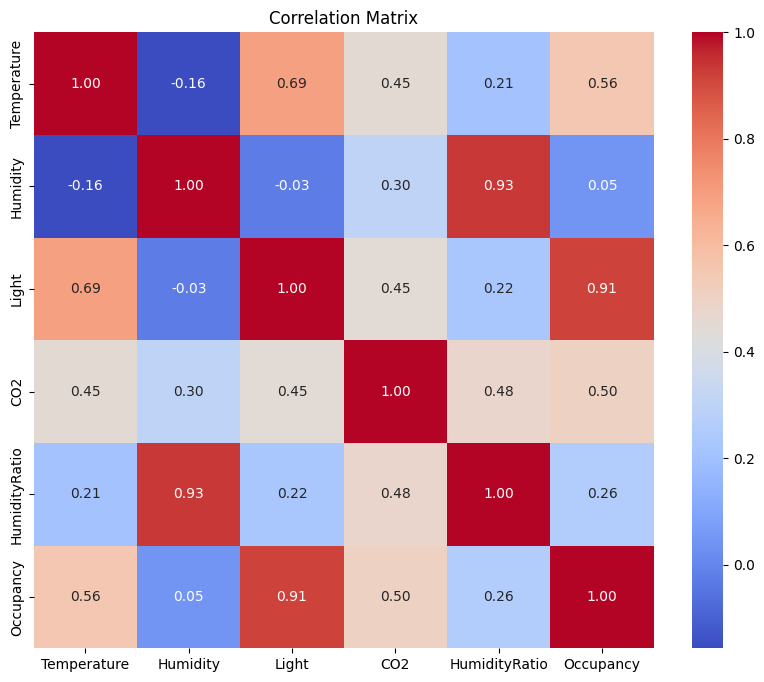

In [ ]:
# Calculăm matricea de corelație pentru datasetul curățat.
corr = df_clean.corr(numeric_only=True)

# Setăm dimensiunea figurii.
plt.figure(figsize=(10, 8))

# Desenăm matricea de corelație.
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

# Adăugăm titlul graficului.
plt.title("Correlation Matrix")

# Afișăm graficul.
plt.show()

In [ ]:
# Definim modelele pe care vrem să le comparăm.
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=42))
    ])
}

# Inițializăm o listă în care salvăm rezultatele.
model_results = []

# Parcurgem fiecare model.
for name, model in models.items():

    # Pornim cronometrul pentru antrenare.
    start_train = time.time()

    # Antrenăm modelul.
    model.fit(X_train, y_train)

    # Calculăm timpul de antrenare.
    train_time = time.time() - start_train

    # Pornim cronometrul pentru predicție.
    start_pred = time.time()

    # Calculăm predicțiile.
    y_pred_model = model.predict(X_test)

    # Calculăm timpul de predicție.
    inference_time = time.time() - start_pred

    # Calculăm probabilitățile pentru clasa 1.
    y_prob_model = model.predict_proba(X_test)[:, 1]

    # Salvăm metricile în listă.
    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred_model),
        "Precision": precision_score(y_test, y_pred_model),
        "Recall": recall_score(y_test, y_pred_model),
        "F1-score": f1_score(y_test, y_pred_model),
        "ROC-AUC": roc_auc_score(y_test, y_prob_model),
        "Training Time": train_time,
        "Inference Time": inference_time
    })

# Transformăm lista într-un DataFrame.
model_results_df = pd.DataFrame(model_results)

# Afișăm tabelul.
model_results_df

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time,Inference Time
0,Logistic Regression,0.988911,0.959350,0.994103,0.976417,0.993328,0.061226,0.007191
1,Decision Tree,0.990272,0.984655,0.973041,0.978814,0.984244,0.079069,0.002552
2,Random Forest,0.992996,0.982397,0.987363,0.984874,0.998583,2.241643,0.146779
3,SVM,0.989494,0.960195,0.995788,0.977667,0.991658,3.976509,0.119700


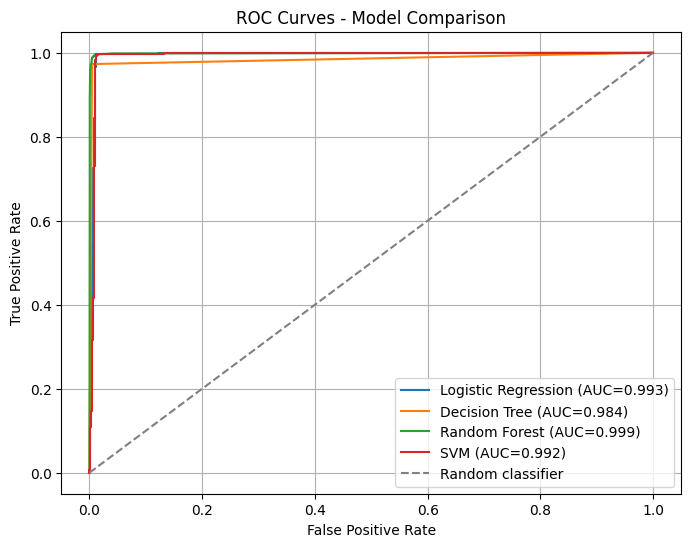

In [ ]:
plt.figure(figsize=(8, 6))

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC={roc_auc_score(y_test, y_prob):.3f})")

for name, model in fitted_models.items():
    y_prob_model = model.predict_proba(X_test)[:, 1]
    fpr_m, tpr_m, _ = roc_curve(y_test, y_prob_model)
    plt.plot(fpr_m, tpr_m, label=f"{name} (AUC={roc_auc_score(y_test, y_prob_model):.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Model Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Inițializăm lista pentru rezultatele ablation study.
ablation_results = []

# Testăm combinații cu 1, 2, 3, 4 și 5 senzori.
for r in range(1, len(all_features) + 1):

    # Generăm toate combinațiile posibile de r senzori.
    for feature_subset in combinations(all_features, r):

        # Transformăm combinația în listă.
        feature_subset = list(feature_subset)

        # Selectăm datele pentru combinația curentă.
        X_subset = df_clean[feature_subset]

        # Target-ul rămâne Occupancy.
        y_subset = df_clean[target]

        # Împărțim datele în train și test.
        X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
            X_subset,
            y_subset,
            test_size=0.25,
            random_state=42,
            stratify=y_subset
        )

        # Construim modelul.
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("lr", LogisticRegression(max_iter=1000))
        ])

        # Antrenăm modelul.
        model.fit(X_train_a, y_train_a)

        # Calculăm predicțiile.
        y_pred_a = model.predict(X_test_a)

        # Calculăm probabilitățile.
        y_prob_a = model.predict_proba(X_test_a)[:, 1]

        # Salvăm rezultatele.
        ablation_results.append({
            "Number of Sensors": len(feature_subset),
            "Sensors": ", ".join(feature_subset),
            "Accuracy": accuracy_score(y_test_a, y_pred_a),
            "Precision": precision_score(y_test_a, y_pred_a),
            "Recall": recall_score(y_test_a, y_pred_a),
            "F1-score": f1_score(y_test_a, y_pred_a),
            "ROC-AUC": roc_auc_score(y_test_a, y_prob_a)
        })

# Transformăm rezultatele în DataFrame.
ablation_df = pd.DataFrame(ablation_results)

# Sortăm rezultatele după ROC-AUC descrescător și apoi după numărul de senzori crescător.
ablation_df = ablation_df.sort_values(
    by=["ROC-AUC", "Number of Sensors"],
    ascending=[False, True]
)

# Afișăm cele mai bune 15 combinații.
ablation_df.head(15)

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Number of Sensors,Sensors,Accuracy,Precision,Recall,F1-score,ROC-AUC
21,3,"Humidity, Light, CO2",0.988716,0.958570,0.994103,0.976013,0.993757
24,3,"Light, CO2, HumidityRatio",0.988716,0.958570,0.994103,0.976013,0.993639
12,2,"Light, CO2",0.988911,0.959350,0.994103,0.976417,0.993524
29,4,"Humidity, Light, CO2, HumidityRatio",0.988911,0.959350,0.994103,0.976417,0.993387
9,2,"Humidity, Light",0.987549,0.953921,0.994103,0.973597,0.993372
28,4,"Temperature, Light, CO2, HumidityRatio",0.988911,0.959350,0.994103,0.976417,0.993329
30,5,"Temperature, Humidity, Light, CO2, HumidityRatio",0.988911,0.959350,0.994103,0.976417,0.993328
25,4,"Temperature, Humidity, Light, CO2",0.988911,0.959350,0.994103,0.976417,0.993317
13,2,"Light, HumidityRatio",0.987743,0.954693,0.994103,0.973999,0.993262
22,3,"Humidity, Light, HumidityRatio",0.987938,0.955466,0.994103,0.974401,0.992907


In [ ]:
# Definim funcția de decizie robotică.
def decision_system(probability):

    # Dacă probabilitatea este sub 0.40, mediul este considerat sigur.
    if probability < 0.40:
        return "MOVE / SAFE"

    # Dacă probabilitatea este între 0.40 și 0.70, robotul trebuie să fie precaut.
    elif probability < 0.70:
        return "SLOW DOWN / CAUTION"

    # Dacă probabilitatea este peste 0.70, mediul este considerat ocupat sau riscant.
    else:
        return "STOP / OCCUPIED AREA"

In [ ]:
# Aplicăm sistemul de decizie pentru fiecare probabilitate prezisă.
robotic_decisions = [
    decision_system(probability)
    for probability in y_prob
]

# Construim un tabel cu probabilitatea, decizia și valoarea reală.
decision_df = pd.DataFrame({
    "Predicted Probability": y_prob,
    "Robotic Decision": robotic_decisions,
    "Real Occupancy": y_test.values
})

# Afișăm primele 20 de decizii.
decision_df.head(20)

,Predicted Probability,Robotic Decision,Real Occupancy
0,0.000195,MOVE / SAFE,0
1,0.000942,MOVE / SAFE,0
2,0.000118,MOVE / SAFE,0
3,0.000140,MOVE / SAFE,0
4,0.000105,MOVE / SAFE,0
5,0.011243,MOVE / SAFE,0
6,0.000162,MOVE / SAFE,0
7,0.000754,MOVE / SAFE,0
8,0.105836,MOVE / SAFE,0
9,0.000467,MOVE / SAFE,0


In [ ]:
# ============================================================
# SIMULARE INTERACTIVĂ VALIDATĂ PENTRU ROBOT
# Acceptă doar valori aflate în intervalele reale din dataset.
# ============================================================

features = ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']


# ============================================================
# 1. INTERVALE REALE DIN DATASET
# ============================================================

ranges = {}

print("INTERVALE ACCEPTATE DIN DATASET")
print("-" * 70)

for feature in features:
    min_value = df_clean[feature].min()
    max_value = df_clean[feature].max()

    ranges[feature] = {
        "min": min_value,
        "max": max_value
    }

    print(
        f"{feature}: "
        f"{round(min_value, 2)} - {round(max_value, 2)}"
    )


# ============================================================
# 2. FUNCȚIE CARE ACCEPTĂ DOAR VALORI CORECTE
# ============================================================

def read_valid_sensor_value(feature_name):

    min_value = ranges[feature_name]["min"]
    max_value = ranges[feature_name]["max"]

    while True:
        try:
            value = float(
                input(
                    f"Introdu valoarea pentru {feature_name} "
                    f"[{round(min_value, 2)} - {round(max_value, 2)}]: "
                )
            )

            if value < min_value or value > max_value:
                print(
                    f"Valoare invalidă. Pentru {feature_name}, "
                    f"introdu o valoare între "
                    f"{round(min_value, 2)} și {round(max_value, 2)}."
                )
            else:
                return value

        except ValueError:
            print("Valoare invalidă. Introdu un număr.")


# ============================================================
# 3. CITIREA VALORILOR DE LA UTILIZATOR
# ============================================================

temperature_value = read_valid_sensor_value('Temperature')
humidity_value = read_valid_sensor_value('Humidity')
light_value = read_valid_sensor_value('Light')
co2_value = read_valid_sensor_value('CO2')
humidity_ratio_value = read_valid_sensor_value('HumidityRatio')


# ============================================================
# 4. CONSTRUIM EXEMPLUL INTRODUS
# ============================================================

manual_input = pd.DataFrame({
    'Temperature': [temperature_value],
    'Humidity': [humidity_value],
    'Light': [light_value],
    'CO2': [co2_value],
    'HumidityRatio': [humidity_ratio_value]
})

print("\nVALORI INTRODUSE:")
display(manual_input)


# ============================================================
# 5. PREDICȚIA MODELULUI
# ============================================================

probability_occupied = model.predict_proba(
    manual_input[features]
)[:, 1][0]


# ============================================================
# 6. DECIZIA ROBOTULUI
# ============================================================

if probability_occupied < 0.40:
    robot_decision = "ROBOTUL ÎNAINTEAZĂ"

elif probability_occupied < 0.70:
    robot_decision = "ROBOTUL ÎNCETINEȘTE"

else:
    robot_decision = "ROBOTUL SE OPREȘTE"


# ============================================================
# 7. REZULTAT FINAL
# ============================================================

print("\nREZULTATUL SIMULĂRII")
print("-" * 70)

print("Probabilitate ocupare:", round(probability_occupied, 2))
print("Decizie robot:", robot_decision)


# ============================================================
# 8. INTERPRETARE
# ============================================================

if probability_occupied < 0.40:
    print("""
Camera pare liberă.
Robotul își poate continua deplasarea.
""")

elif probability_occupied < 0.70:
    print("""
Situația este incertă.
Robotul trebuie să încetinească.
""")

else:
    print("""
Camera pare ocupată.
Robotul trebuie să se oprească.
""")


# ============================================================
# 9. EXPLICAȚIE SPECIALĂ PENTRU LUMINĂ
# ============================================================

print("\nANALIZA LUMINII")
print("-" * 70)

if light_value == 0:
    print("""
Light = 0.
Nu există lumină detectată.
În acest caz, robotul trebuie să se bazeze și pe ceilalți senzori.
""")

elif light_value < 100:
    print("""
Lumina este foarte slabă.
Poate fi apus, răsărit sau lumină ambientală redusă.
""")

elif light_value < 300:
    print("""
Lumina este într-o zonă incertă.
Robotul trebuie să interpreteze și CO2, temperatura și umiditatea.
""")

else:
    print("""
Lumina este ridicată.
În dataset, acest lucru este frecvent asociat cu o cameră ocupată.
""")

INTERVALE ACCEPTATE DIN DATASET
----------------------------------------------------------------------
Temperature: 19.0 - 24.41
Humidity: 16.75 - 39.5
Light: 0.0 - 1697.25
CO2: 412.75 - 2076.5
HumidityRatio: 0.0 - 0.01
Introdu valoarea pentru Temperature [19.0 - 24.41]: 23
Introdu valoarea pentru Humidity [16.75 - 39.5]: 30
Introdu valoarea pentru Light [0.0 - 1697.25]: 500
Introdu valoarea pentru CO2 [412.75 - 2076.5]: 1200
Introdu valoarea pentru HumidityRatio [0.0 - 0.01]: 0.0048

VALORI INTRODUSE:


,Temperature,Humidity,Light,CO2,HumidityRatio
0,23.0,30.0,500.0,1200.0,0.0048



REZULTATUL SIMULĂRII
----------------------------------------------------------------------
Probabilitate ocupare: 0.99
Decizie robot: ROBOTUL SE OPREȘTE

Camera pare ocupată.
Robotul trebuie să se oprească.


ANALIZA LUMINII
----------------------------------------------------------------------

Lumina este ridicată.
În dataset, acest lucru este frecvent asociat cu o cameră ocupată.



In [ ]:
# Definim lista de variabile pentru modelul care folosește doar Light.
only_light_features = ["Light"]

# Definim lista de variabile pentru modelul care exclude Light.
without_light_features = ["Temperature", "Humidity", "CO2", "HumidityRatio"]

# Inițializăm o listă pentru rezultatele comparației.
light_comparison_results = []

# Definim un dicționar cu cele două scenarii pe care vrem să le testăm.
light_scenarios = {
    # Primul scenariu folosește doar variabila Light.
    "Only Light": only_light_features,

    # Al doilea scenariu folosește toate variabilele în afară de Light.
    "Without Light": without_light_features
}

# Parcurgem fiecare scenariu definit mai sus.
for scenario_name, scenario_features in light_scenarios.items():

    # Selectăm variabilele de intrare pentru scenariul curent.
    X_scenario = df_clean[scenario_features]

    # Selectăm variabila țintă.
    y_scenario = df_clean[target]

    # Împărțim datele în train și test pentru scenariul curent.
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        # Datele de intrare.
        X_scenario,

        # Clasele reale.
        y_scenario,

        # Folosim 25% din date pentru testare.
        test_size=0.25,

        # Fixăm random_state pentru rezultate reproductibile.
        random_state=42,

        # Păstrăm proporția claselor în train și test.
        stratify=y_scenario
    )

    # Construim pipeline-ul cu standardizare și logistic regression.
    scenario_model = Pipeline([
        # Standardizăm variabilele.
        ("scaler", StandardScaler()),

        # Antrenăm modelul Logistic Regression.
        ("lr", LogisticRegression(max_iter=1000))
    ])

    # Măsurăm timpul înainte de antrenare.
    start_train_time = time.time()

    # Antrenăm modelul pe datele de train.
    scenario_model.fit(X_train_s, y_train_s)

    # Calculăm timpul de antrenare.
    train_time = time.time() - start_train_time

    # Măsurăm timpul înainte de predicție.
    start_pred_time = time.time()

    # Calculăm predicțiile binare.
    y_pred_s = scenario_model.predict(X_test_s)

    # Calculăm probabilitatea pentru clasa 1.
    y_prob_s = scenario_model.predict_proba(X_test_s)[:, 1]

    # Calculăm timpul de predicție.
    pred_time = time.time() - start_pred_time

    # Adăugăm rezultatele scenariului curent în listă.
    light_comparison_results.append({
        # Salvăm numele scenariului.
        "Scenario": scenario_name,

        # Salvăm variabilele folosite.
        "Features": ", ".join(scenario_features),

        # Salvăm numărul de variabile folosite.
        "Number of Features": len(scenario_features),

        # Calculăm accuracy.
        "Accuracy": accuracy_score(y_test_s, y_pred_s),

        # Calculăm precision.
        "Precision": precision_score(y_test_s, y_pred_s),

        # Calculăm recall.
        "Recall": recall_score(y_test_s, y_pred_s),

        # Calculăm F1-score.
        "F1-score": f1_score(y_test_s, y_pred_s),

        # Calculăm ROC-AUC.
        "ROC-AUC": roc_auc_score(y_test_s, y_prob_s),

        # Salvăm timpul de antrenare.
        "Training Time": train_time,

        # Salvăm timpul de predicție.
        "Prediction Time": pred_time
    })

    # Salvăm modelul doar cu Light pentru analize ulterioare.
    if scenario_name == "Only Light":
        # Reținem modelul doar cu Light.
        only_light_model = scenario_model

        # Reținem setul de test pentru modelul doar cu Light.
        X_test_only_light = X_test_s

        # Reținem clasele reale pentru modelul doar cu Light.
        y_test_only_light = y_test_s

    # Salvăm modelul fără Light pentru analize ulterioare.
    if scenario_name == "Without Light":
        # Reținem modelul fără Light.
        without_light_model = scenario_model

        # Reținem setul de test pentru modelul fără Light.
        X_test_without_light = X_test_s

        # Reținem clasele reale pentru modelul fără Light.
        y_test_without_light = y_test_s

# Transformăm lista de rezultate într-un DataFrame.
light_comparison_df = pd.DataFrame(light_comparison_results)

# Rotunjim valorile numerice pentru afișare.
light_comparison_df = light_comparison_df.round(4)

# Afișăm comparația dintre modelul doar cu Light și modelul fără Light.
light_comparison_df

,Scenario,Features,Number of Features,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time,Prediction Time
0,Only Light,Light,1,0.9860,0.9471,0.9949,0.9704,0.9924,0.3015,0.0300
1,Without Light,"Temperature, Humidity, CO2, HumidityRatio",4,0.8226,0.6387,0.5333,0.5813,0.9049,0.1819,0.0236
